# Repeat Purchase Prediction, part 2
# Data Preprocessing

## Notebook purpose

This notebook turns the raw tables into data a model can use. It follows `01_eda.ipynb`, which found what is wrong with the data and what can be used at prediction time. Here we decide what to do about each finding, test the decisions that are not obvious, and save the result.

The target is `repeat_purchase_90d`: whether a customer buys again within 90 days of a purchase. The competition scores F1, so choices such as the validation design and the threshold are made with F1 in mind rather than accuracy.

This notebook covers:

- Merging the customer table and fixing the problems found in the EDA: placeholder values standing in for missing information, wrong signs, calculation inconsistencies and empty rows;
- Building a validation scheme that respects time order;
- Comparing the main treatment options (missing values, outliers, transformations, scaling, encoding) with the same models and the same folds;
- Feature engineering and feature selection;
- Saving the cleaned data, a decision log and the preprocessing steps in a form that can be reused on the test set.

## Analysis principles

A few rules apply to the whole notebook, and most of them come from the EDA (section 13).

- **Two kinds of steps:**
    - *Stateless* steps work row by row and need nothing learned from the data: fixing a placeholder, recomputing a mean from its own total and count, building a ratio.
    - *Stateful* steps learn something from the data (fill values, encoding maps, scaling, feature selection) and are fitted only on the training part of each fold.
- **Time order.** The predictors describe the customer's history up to the purchase, and the target describes the next 90 days. Validation therefore uses later periods than training, with a 90-day gap between them. A random split would overstate the scores.
- **No information from later rows.** A feature may not use any later purchase of the same customer, in train or in test.
- **Decisions are tested, not assumed.** When two treatments are reasonable, they are compared with the same model and the same folds. The simpler one is kept unless the other is clearly better. Clearly better means the 95% bootstrap interval of the F1 difference, with customers rather than rows as the resampling unit, stays above zero. Section 7 adds one variant: when two options score the same, the one with fewer columns is kept.
- **Everything that changes data is logged.** Each decision records the column, the action, the reason and the number of rows affected.
- **Test data is never used to fit anything.**

## Planned structure

1. **Setup and data loading:** paths, packages and constants; loading `train`, `test` and the customer table
2. **Stateless cleaning:**
   - 2.1. Merge the customer table and check dates
   - 2.2. Remove rows without a date
   - 2.3. Replace placeholders with missing values
   - 2.4. Repair inconsistent columns
   - 2.5. Sanity checks on the test set
3. **Validation design:**
   - 3.1. Expanding yearly folds
   - 3.2. How options are compared and how the threshold is chosen
4. **Reference models:**
   - 4.1. Scoring on the folds
5. **Treatment comparisons:**
   - 5.1. Invalid values
   - 5.2. Missing values
   - 5.3. Outliers
   - 5.4. Transformations and scaling
   - 5.5. Encoding the large categorical columns
   - 5.6. Customer-table fields
   - 5.7. Summary of treatment decisions
6. **Feature engineering:**
   - 6.1. Ratio and marker features
   - 6.2. Calendar features
   - 6.3. The customer's past repeat rate
7. **Feature selection and dimensionality reduction:**
   - 7.1. Domain knowledge
   - 7.2. Noise probe
   - 7.3. Filter methods
   - 7.4. Wrapper and embedded methods
   - 7.5. Reduction and vote
   - 7.6. Chaining a second selector before elastic net
   - 7.7. Stability of elastic net
8. **Final preprocessing and outputs:**
   - 8.1. Stateless cleaning from the module
   - 8.2. Sanity check of the final pipelines
   - 8.3. Saving the outputs
9. **Summary of decisions**

# 1. Setup and data loading

In [1]:
# Handle file paths without relying on computer-specific locations.
from pathlib import Path

# Locate the project from the current folder or one of its parent folders.
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data").is_dir()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

# Give a clear error if the expected project structure cannot be found.
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project. Open the notebook within the repository."
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                  # original files, never modified
PROCESSED_DIR = DATA_DIR / "preprocessed"   # outputs of this notebook
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Check the expected datasets without loading their contents.
DATA_FILES = [
    "train.csv",
    "test.csv",
    "clientes.csv",
    "sample_submission.csv",
]

total_size_mib = 0

for filename in DATA_FILES:
    file_path = RAW_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(f"Missing dataset: {file_path}")

    # Convert file size from bytes to mebibytes (MiB).
    size_mib = file_path.stat().st_size / (1024 ** 2)
    total_size_mib += size_mib

    print(f"{filename}: {size_mib:,.2f} MiB")

print(f"\nTotal size: {total_size_mib:,.2f} MiB")

train.csv: 2.39 MiB
test.csv: 0.36 MiB
clientes.csv: 0.34 MiB
sample_submission.csv: 0.01 MiB

Total size: 3.11 MiB


## 1.1. Imports and Display Settings

Import the libraries used throughout the analysis and configure display
settings to keep tables readable and plots consistent.

In [2]:
# Standard library
import sys
import json
from functools import partial

# Data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Notebook display
from IPython.display import display

# Statistical tests used by the selection filters
from scipy.stats import chi2_contingency, pointbiserialr

# Base classes for the custom transformers and selectors
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone

# Stateful preprocessing, fitted inside each training fold only
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (needed before IterativeImputer)
from sklearn.impute import SimpleImputer, IterativeImputer, KNNImputer
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
    PowerTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder
)

# Feature selection and reduction
from sklearn.feature_selection import (
    RFE,
    SelectFromModel,
    SelectKBest,
    SelectorMixin,
    VarianceThreshold,
    mutual_info_classif,
)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA

# Reference models: linear branch and tree branch
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Metrics: F1 decides, log-loss and ROC-AUC are reported alongside
from sklearn.metrics import f1_score, log_loss, roc_auc_score

# Project code in <project>/src
sys.path.insert(0, str(PROJECT_ROOT))
from src.decision_log import DecisionLog
import src.repeat_purchase_prep as rpp

# Constants used across the notebook
RANDOM_STATE = 42
target = "repeat_purchase_90d"
TOL = 0.01                          # tolerance for cent rounding
PLACEHOLDER_DAYS = -4               # impossible interval value found in the EDA
PLACEHOLDER_AMOUNT = 1_000_000_000  # impossible amount filler found in the EDA

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

# Plot style
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## 1.2. Data Loading

In [3]:
# Load the datasets into separate DataFrames
train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")
clientes = pd.read_csv(RAW_DIR / "clientes.csv")
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv")

# Group the datasets to inspect them consistently
datasets = {
    "train": train,
    "test": test,
    "clientes": clientes,
    "sample_submission": sample_submission,
}

# Show the dimensions, column names and first five rows of each dataset
for name, df in datasets.items():
    print(f"\nDataset: {name}")
    print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
    print(f"Columns: {df.columns.tolist()}")

    display(df.head())


Dataset: train
Rows: 6,534 | Columns: 39
Columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'repeat_purchase_90d', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.110,510.900,453.750,104.360,0.000,0.000,57.150,153.100,4.000,1.000,1,79.000,126.000,2.000,858.300,429.150,112.656,349.490,508.810,47.000,NaN,0.000,0.000,1.000,349.490,2.000,858.300,2.000,858.300,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660
1,978.800,830.020,795.770,183.030,0.000,0.000,34.250,472.943,32.000,1.000,1,244.000,616.000,5.000,"6,722.830","1,344.566","1,683.795",84.380,"4,222.150",93.000,117.658,0.000,0.000,0.000,0.000,0.000,0.000,4.000,"2,500.680",189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.925
2,10.330,12.000,8.400,1.930,0.000,0.000,3.600,6.097,1.000,1.000,1,9.000,610.000,90.000,"17,590.080",195.445,190.390,4.540,"1,002.150",6.753,6.384,2.000,111.270,9.000,"1,928.550",28.000,"5,290.250",49.000,"7,899.800",103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.259
3,856.830,696.610,696.610,160.220,0.000,0.000,0.000,408.167,9.000,1.000,0,97.000,97.000,1.000,270.330,270.330,NaN,270.330,270.330,NaN,NaN,0.000,0.000,0.000,0.000,1.000,270.330,1.000,270.330,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448
4,"1,616.100","1,488.850","1,313.900",302.200,0.000,0.000,174.950,485.402,33.000,1.000,1,85.000,"1,575.000",25.000,"12,803.020",512.121,406.697,22.580,"1,736.740",62.083,66.247,0.000,0.000,2.000,184.130,4.000,"2,062.500",4.000,"2,062.500",122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.059



Dataset: test
Rows: 986 | Columns: 38
Columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.370,582.050,232.820,53.550,0.000,0.000,349.230,104.409,22,1,40.000,3905,122,"46,287.230",379.404,528.298,2.720,"3,198.000",31.942,48.035,0,0.000,6,"1,295.820",9,"2,498.900",23,"9,140.120",519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.622
1,"1,949.250","1,725.000","1,725.000",224.250,0.000,0.000,0.000,0.000,1,1,63.000,3613,58,"243,340.480","4,195.526","2,545.945",569.520,"11,031.740",62.281,46.416,0,0.000,1,"3,137.110",2,"5,086.360",4,"16,252.350",942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.319
2,"2,738.710","4,114.830","2,738.710",0.000,0.000,0.000,"1,376.120","1,019.467",99,1,230.000,1786,16,"21,570.230","1,348.139","1,096.651",40.090,"3,363.230",103.733,78.583,0,0.000,0,0.000,0,0.000,4,"4,570.760",386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.252
3,726.980,591.040,591.040,135.940,0.000,0.000,0.000,341.649,39,2,234.000,374,3,"3,907.610","1,302.537",881.237,296.370,"1,937.150",70.000,67.882,0,0.000,0,0.000,0,0.000,2,"1,970.460",588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988
4,670.760,555.490,545.330,125.430,0.000,0.000,10.160,326.716,13,1,NaN,386,5,"4,877.080",975.416,334.407,546.280,"1,305.090",77.000,43.825,0,0.000,1,759.060,2,"2,062.370",4,"4,330.800",610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.512



Dataset: clientes
Rows: 1,143 | Columns: 13
Columns: ['customer_id', 'country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name', 'customer_since_year']


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



Dataset: sample_submission
Rows: 986 | Columns: 2
Columns: ['ID', 'repeat_purchase_90d']


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


# 2. Stateless cleaning
## 2.1. Merge the customer table and check dates

The customer table (`clientes`) adds one row of attributes per customer. It is joined to `train` and `test` with a left join on `customer_id`.

Dates are parsed with a fixed format so that a malformed value fails instead of becoming a silent missing value. Rows are then sorted by `purchase_date`, with `ID` as a tie-breaker, because it is time-dependent.

This step also starts the decision log. Every change to the data is recorded with its reason and the number of rows affected in train and test.

In [4]:
# Call the log helper
log = DecisionLog()

# Creating copies from the raw file
train_clean = train.copy()
test_clean = test.copy()

# The customer table must have one row per customer, or the merge duplicates rows
assert clientes["customer_id"].is_unique, "clientes has repeated customer_id"

# Only the key may be shared between the tables
shared = (set(train.columns) | set(test.columns)) & set(clientes.columns)
assert shared == {"customer_id"}, f"Unexpected shared columns: {shared}"

# Coverage before merging: how many rows have a customer record
matched = {}
for name, df in [("train", train_clean), ("test", test_clean)]:
    matched[name] = int(df["customer_id"].isin(clientes["customer_id"]).sum())
    print(f"{name}: {matched[name]:,} of {len(df):,} rows have a customer record")

train: 6,534 of 6,534 rows have a customer record
test: 986 of 986 rows have a customer record


In [5]:
# Left join keeps every purchase row & many_to_one ensures no duplicates.
n_train, n_test = len(train_clean), len(test_clean)
train_clean = train_clean.merge(clientes, on="customer_id", how="left", validate="many_to_one")
test_clean = test_clean.merge(clientes, on="customer_id", how="left", validate="many_to_one")
assert len(train_clean) == n_train and len(test_clean) == n_test, "Merge changed row count"

log.record(
    "D1", "customer_id", "left join clientes (many_to_one)",
    "Add customer attributes without changing the number of purchase rows.",
    matched["train"], matched["test"],
    carries={"on": "customer_id", "how": "left", "validate": "many_to_one"},
)

In [6]:
# Strict date parsing: a wrong format raises an error, missing stays NaN.
for df in (train_clean, test_clean):
    df["purchase_date"] = pd.to_datetime(df["purchase_date"], format="%Y-%m-%d")

log.record(
    "D2", "purchase_date", "parse as datetime, format %Y-%m-%d",
    "Time order is needed for validation; strict format avoids silent errors.",
    int(train_clean["purchase_date"].notna().sum()),
    int(test_clean["purchase_date"].notna().sum()),
    carries={"format": "%Y-%m-%d"},
)

# Date summary per dataset.
date_summary = pd.DataFrame(
    {
        name: {
            "rows": len(df),
            "missing_date": int(df["purchase_date"].isna().sum()),
            "first_date": df["purchase_date"].min().date(),
            "last_date": df["purchase_date"].max().date(),
        }
        for name, df in [("train", train_clean), ("test", test_clean)]
    }
).T
display(date_summary)

,rows,missing_date,first_date,last_date
train,6534,65,2015-07-11,2025-02-15
test,986,0,2025-05-24,2026-10-06


In [7]:
# Test should come after train in time
train_last = train_clean["purchase_date"].max()
test_first = test_clean["purchase_date"].min()
print(f"Train last date: {train_last.date()} | Test first date: {test_first.date()}")
print(f"Test starts after train ends: {test_first > train_last}")

# Customer cannot buy before the year they became a customer
for name, df in [("train", train_clean), ("test", test_clean)]:
    too_early = int((df["purchase_date"].dt.year < df["customer_since_year"]).sum())
    print(f"{name}: {too_early:,} rows with purchase year before customer_since_year")

# ID must be unique across both files 
all_ids = pd.concat([train_clean["ID"], test_clean["ID"]])
assert all_ids.is_unique, "Repeated ID across train/test"

# Sort by time. Missing dates go last
train_clean = train_clean.sort_values(["purchase_date", "ID"], kind="stable").reset_index(drop=True)
test_clean = test_clean.sort_values(["purchase_date", "ID"], kind="stable").reset_index(drop=True)

log.record(
    "D3", "purchase_date", "sort by purchase_date then ID",
    "Time-ordered folds need rows in date order; ID makes ties deterministic.",
    len(train_clean), len(test_clean),
    carries={"by": ["purchase_date", "ID"]},
)

display(log.to_frame())

Train last date: 2025-02-15 | Test first date: 2025-05-24
Test starts after train ends: True
train: 0 rows with purchase year before customer_since_year
test: 0 rows with purchase year before customer_since_year


,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986


## 2.2. Removing missing records

65 rows in `train` have no `purchase_date`. Without a date a row cannot be placed in time, so it cannot be used for validation. Before dropping them, let's look at what else is filled in on those rows.

In [8]:
# Rows with no purchase date
no_date = train_clean["purchase_date"].isna()
print(f"Rows without a date: {no_date.sum()}")

# Original columns only, leaving out keys, target and date
purchase_cols = [
    c for c in train.columns
    if c not in ["ID", "customer_id", "repeat_purchase_90d", "purchase_date"]
]

# Which columns still have a value on these rows?
filled = train_clean.loc[no_date, purchase_cols].notna().sum()
print("\nColumns with a value on these rows:")
print(filled[filled > 0])

# What does the target look like on these rows?
print("\nTarget on these rows:")
print(train_clean.loc[no_date, "repeat_purchase_90d"].value_counts().to_dict())

Rows without a date: 65

Columns with a value on these rows:
Series([], dtype: int64)

Target on these rows:
{1: 33, 0: 32}


Rows with no date are removed from `train`. `test` has no missing dates, so it stays as it is.

In [9]:
# Drop the rows without a date
n_before = len(train_clean)
train_clean = train_clean.loc[~no_date].reset_index(drop=True)
n_dropped = n_before - len(train_clean)
print(f"Rows removed: {n_dropped} | Rows left: {len(train_clean):,}")

# Both files should now have a date on every row
assert train_clean["purchase_date"].notna().all()
assert test_clean["purchase_date"].notna().all()

# Test has no missing dates, so nothing is dropped there
log.record(
    "D4", "purchase_date", "drop rows with no purchase_date",
    "Rows without a date cannot be placed in time. Train only, test has none.",
    n_dropped, 0,
    carries={"drop_if_missing": "purchase_date"},
)

display(log.to_frame())

Rows removed: 65 | Rows left: 6,469


,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986
3,D4,purchase_date,drop rows with no purchase_date,"Rows without a date cannot be placed in time. Train only, test has none.",65,0


## 2.3. Replacing placeholders with missing values

Two filler values showed up in the EDA. A value of -4 appears in the day-interval columns, and a value of 1,000,000,000 appears in some amount columns. A gap of -4 days or a purchase of one billion is not real, so both are turned into missing values.

The rule looks at one row at a time, so it is applied to train and test in the same way. First we count both values in every numeric column, to make sure they only show up where we expect.

In [10]:
numeric_cols = train_clean.select_dtypes("number").columns

# Test has no target column, so reindex to compare the same columns
test_numeric = test_clean.reindex(columns=numeric_cols)

# Count both filler values in every numeric column
scan = pd.DataFrame({
    "days_train": (train_clean[numeric_cols] == PLACEHOLDER_DAYS).sum(),
    "days_test": (test_numeric == PLACEHOLDER_DAYS).sum(),
    "amount_train": (train_clean[numeric_cols] == PLACEHOLDER_AMOUNT).sum(),
    "amount_test": (test_numeric == PLACEHOLDER_AMOUNT).sum(),
})

# Show only the columns where something was found
display(scan[(scan > 0).any(axis=1)])

,days_train,days_test,amount_train,amount_test
days_since_previous_purchase,16,2,0,0
prior_mean_purchase_value,0,0,16,2
prior_mean_gap_days,16,2,0,0
spend_365d,0,0,15,2


The -4 is replaced only in the two interval columns, where a negative number of days makes no sense. The billion is replaced in every column where it was found, since no real purchase gets near that value.

In [11]:
interval_cols = ["days_since_previous_purchase", "prior_mean_gap_days"]

# Amount columns are taken from the scan above
amount_cols = scan.index[(scan["amount_train"] + scan["amount_test"]) > 0].tolist()

jobs = [
    ("D5", interval_cols, PLACEHOLDER_DAYS, "Negative day count is impossible"),
    ("D6", amount_cols, PLACEHOLDER_AMOUNT, "A value of one billion is a filler, not a purchase"),
]

for step, cols, value, reason in jobs:
    for col in cols:
        n_train = int((train_clean[col] == value).sum())
        n_test = int((test_clean[col] == value).sum())

        train_clean[col] = train_clean[col].replace(value, np.nan)
        test_clean[col] = test_clean[col].replace(value, np.nan)

        log.record(
            step, col, f"replace {value:,} with missing", reason,
            n_train, n_test,
            carries={"column": col, "replace": value, "with": None},
        )

# Nothing should be left in the columns we cleaned
for col in interval_cols:
    assert not (train_clean[col] == PLACEHOLDER_DAYS).any()
    assert not (test_clean[col] == PLACEHOLDER_DAYS).any()
for col in amount_cols:
    assert not (train_clean[col] == PLACEHOLDER_AMOUNT).any()
    assert not (test_clean[col] == PLACEHOLDER_AMOUNT).any()

display(log.to_frame())

,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986
3,D4,purchase_date,drop rows with no purchase_date,"Rows without a date cannot be placed in time. Train only, test has none.",65,0
4,D5,days_since_previous_purchase,replace -4 with missing,Negative day count is impossible,16,2
5,D5,prior_mean_gap_days,replace -4 with missing,Negative day count is impossible,16,2
6,D6,prior_mean_purchase_value,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",16,2
7,D6,spend_365d,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",15,2


## 2.4. Repairing inconsistent columns

Several columns can be checked against each other. Past total spend, past purchase count and past mean purchase should agree. The 365-day spend should sit between the 180-day spend and the lifetime spend. The gaps between purchases should add up to the customer's history.

When two columns disagree, one of them is wrong. Before repairing anything, each rule is tested on the data to see how often it holds. A rule that holds in almost every row is safe to use for repair. A rule that holds half the time is not.

**Check 1.** Do mean, total and count agree, and are the four values equal for customers with exactly one past purchase?

In [12]:
# Mean purchase value and single-purchase rows
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    mean = df["prior_mean_purchase_value"]
    expected = df["prior_total_spend"] / count

    has_prior = count > 0
    comparable = has_prior & mean.notna() & expected.notna()
    matches = comparable & ((mean - expected).abs() <= TOL)

    print(f"--- {name} ---")
    print(f"Rows with a prior purchase:        {has_prior.sum():,}")
    print(f"Mean and total both usable:        {comparable.sum():,}")
    print(f"  mean = total / count:            {matches.sum():,}")
    print(f"  mean disagrees:                  {(comparable & ~matches).sum():,}")
    print(f"  of those, negative mean:         {(comparable & ~matches & (mean < 0)).sum():,}")
    print(f"Mean missing, total available:     {(has_prior & mean.isna() & expected.notna()).sum():,}")
    print(f"Mean missing, total missing:       {(has_prior & mean.isna() & expected.isna()).sum():,}")

    # Rows with exactly one prior purchase: total, mean, min, max should be equal
    one = count == 1
    cols = ["prior_total_spend", "prior_mean_purchase_value",
            "prior_min_purchase_value", "prior_max_purchase_value"]
    usable = one & df[cols].notna().all(axis=1)
    spread = df.loc[usable, cols].max(axis=1) - df.loc[usable, cols].min(axis=1)
    print(f"Single-purchase rows:              {one.sum():,}")
    print(f"  with all four values present:    {usable.sum():,}")
    print(f"  all four equal:                  {(spread <= TOL).sum():,}")
    print()

--- train ---
Rows with a prior purchase:        5,866
Mean and total both usable:        5,656
  mean = total / count:            5,594
  mean disagrees:                  62
  of those, negative mean:         16
Mean missing, total available:     210
Mean missing, total missing:       0
Single-purchase rows:              445
  with all four values present:    424
  all four equal:                  417

--- test ---
Rows with a prior purchase:        964
Mean and total both usable:        932
  mean = total / count:            923
  mean disagrees:                  9
  of those, negative mean:         2
Mean missing, total available:     32
Mean missing, total missing:       0
Single-purchase rows:              24
  with all four values present:    23
  all four equal:                  23



**Check 2.** Is the largest past purchase below the total, and does the 365-day spend sit between the 180-day spend and the lifetime spend?

In [13]:
# Maximum and 365-day spend
for name, df in [("train", train_clean), ("test", test_clean)]:
    print(f"--- {name} ---")

    # The largest past purchase cannot exceed the total of all past purchases
    too_big = df["prior_max_purchase_value"] > df["prior_total_spend"] + TOL
    print(f"prior_max above prior_total_spend: {too_big.sum():,}")

    # Four ways spend_365d can be wrong, plus the missing values from the placeholder step
    s365, s180 = df["spend_365d"], df["spend_180d"]
    c365, c180 = df["purchase_count_365d"], df["purchase_count_180d"]
    conditions = {
        "missing": s365.isna(),
        "negative": s365 < 0,
        "below spend_180d": s365 < s180 - TOL,
        "above prior_total_spend": s365 > df["prior_total_spend"] + TOL,
        "positive with 0 purchases": (s365 > 0) & (c365 == 0),
    }
    for label, mask in conditions.items():
        print(f"spend_365d {label:<26}{mask.sum():,}")

    invalid = pd.concat(conditions, axis=1).any(axis=1)

    # Count identities that let us rebuild the value
    rebuildable = invalid & (
        (c365 == c180) | (c365 == df["prior_purchase_count"]) | (c365 == 0)
    )
    print(f"spend_365d invalid rows:           {invalid.sum():,}")
    print(f"  rebuildable from counts:         {rebuildable.sum():,}")
    print()

--- train ---
prior_max above prior_total_spend: 45
spend_365d missing                   210
spend_365d negative                  15
spend_365d below spend_180d          15
spend_365d above prior_total_spend   39
spend_365d positive with 0 purchases 0
spend_365d invalid rows:           264
  rebuildable from counts:         108

--- test ---
prior_max above prior_total_spend: 6
spend_365d missing                   32
spend_365d negative                  2
spend_365d below spend_180d          2
spend_365d above prior_total_spend   7
spend_365d positive with 0 purchases 0
spend_365d invalid rows:           41
  rebuildable from counts:         5



**Check 3.** Do the gaps between purchases add up to the customer's history? With n past purchases there are n − 1 gaps, so the mean gap times (n − 1) should equal the tenure minus the days since the last purchase.

In [14]:
# Gap identity
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    gap_sum = df["prior_mean_gap_days"] * (count - 1)
    history = df["customer_tenure_days"] - df["days_since_previous_purchase"]

    # Needs at least two past purchases to have a gap
    comparable = (count >= 2) & gap_sum.notna() & history.notna()
    matches = comparable & ((gap_sum - history).abs() <= 0.5)

    print(f"--- {name} ---")
    print(f"Rows with two or more prior purchases: {(count >= 2).sum():,}")
    print(f"  identity can be checked:             {comparable.sum():,}")
    print(f"  identity holds:                      {matches.sum():,}")
    print(f"  identity fails:                      {(comparable & ~matches).sum():,}")
    print(f"Mean gap missing, rebuildable:         "
          f"{((count >= 2) & df['prior_mean_gap_days'].isna() & history.notna()).sum():,}")
    print()

--- train ---
Rows with two or more prior purchases: 5,421
  identity can be checked:             5,031
  identity holds:                      5,031
  identity fails:                      0
Mean gap missing, rebuildable:         203

--- test ---
Rows with two or more prior purchases: 940
  identity can be checked:             877
  identity holds:                      877
  identity fails:                      0
Mean gap missing, rebuildable:         32



**Check 4.** When two values disagree, which one is wrong? A true mean has to sit between the smallest and the largest purchase, and a negative 365-day spend that becomes valid once its sign is flipped points to a sign error.

In [15]:
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    mean = df["prior_mean_purchase_value"]
    lo, hi = df["prior_min_purchase_value"], df["prior_max_purchase_value"]
    expected = df["prior_total_spend"] / count

    # Rows where recorded mean and total/count disagree
    bad = (count > 0) & mean.notna() & expected.notna() & ((mean - expected).abs() > TOL)
    has_range = bad & lo.notna() & hi.notna()

    # A true mean has to sit between the smallest and largest purchase
    def inside(v):
        return (v >= lo - TOL) & (v <= hi + TOL)

    print(f"--- {name} ---")
    print(f"Disagreeing rows with min and max:    {has_range.sum()}")
    print(f"  only total/count fits the range:    {(has_range & inside(expected) & ~inside(mean)).sum()}")
    print(f"  only recorded mean fits:            {(has_range & ~inside(expected) & inside(mean)).sum()}")
    print(f"  both fit:                           {(has_range & inside(expected) & inside(mean)).sum()}")
    print(f"  neither fits:                       {(has_range & ~inside(expected) & ~inside(mean)).sum()}")

    # Negative spend_365d: does the positive value pass the other checks?
    s365 = df["spend_365d"]
    neg = s365 < 0
    flipped = -s365
    flip_ok = neg & (flipped >= df["spend_180d"] - TOL) & (flipped <= df["prior_total_spend"] + TOL)
    print(f"Negative spend_365d:                  {neg.sum()}")
    print(f"  passes checks after flipping sign:  {flip_ok.sum()}")

    # spend_365d above lifetime spend: is the 365-day count also above the lifetime count?
    above = s365 > df["prior_total_spend"] + TOL
    count_above = above & (df["purchase_count_365d"] > count)
    print(f"spend_365d above prior_total_spend:   {above.sum()}")
    print(f"  365-day count also above lifetime:  {count_above.sum()}")
    print()

--- train ---
Disagreeing rows with min and max:    62
  only total/count fits the range:    61
  only recorded mean fits:            0
  both fit:                           1
  neither fits:                       0
Negative spend_365d:                  15
  passes checks after flipping sign:  14
spend_365d above prior_total_spend:   39
  365-day count also above lifetime:  0

--- test ---
Disagreeing rows with min and max:    9
  only total/count fits the range:    8
  only recorded mean fits:            0
  both fit:                           1
  neither fits:                       0
Negative spend_365d:                  2
  passes checks after flipping sign:  2
spend_365d above prior_total_spend:   7
  365-day count also above lifetime:  0



The checks point to the same pattern each time. When mean and total disagree, total / count falls between the smallest and largest purchase and the recorded mean does not. So the total is right and the mean is recomputed from it. The negative 365-day spends become valid after flipping the sign, the same mistake seen in the mean. When the 365-day spend is above the lifetime spend while the counts agree, the spend value is the broken one.

Every repair adds a flag column. Whether the flags help the model is tested in section 5.

One rule is checked before it is used. With exactly one past purchase, the days since the previous purchase should equal the customer's tenure.

In [16]:
# With one past purchase, the previous purchase is also the first one
for name, df in [("train", train_clean), ("test", test_clean)]:
    one = (df["prior_purchase_count"] == 1) & df["days_since_previous_purchase"].notna()
    same = one & ((df["days_since_previous_purchase"] - df["customer_tenure_days"]).abs() <= 0.5)
    print(f"{name}: {same.sum()} of {one.sum()} single-purchase rows have days_since = tenure")


train: 423 of 423 single-purchase rows have days_since = tenure
test: 23 of 23 single-purchase rows have days_since = tenure


In [17]:
def repair_frame(df):
    """Row-by-row repairs. Returns the repaired copy and the rows changed per step."""
    df = df.copy()
    n = {}
    count = df["prior_purchase_count"]
    total = df["prior_total_spend"]

    # Mean purchase value: recompute from total and count
    old_mean = df["prior_mean_purchase_value"]
    new_mean = total / count
    fix_mean = (count > 0) & new_mean.notna() & (
        old_mean.isna() | ((old_mean - new_mean).abs() > TOL)
    )
    df.loc[fix_mean, "prior_mean_purchase_value"] = new_mean[fix_mean]
    n["mean"] = int(fix_mean.sum())

    # One past purchase: mean, min and max all equal the total
    single_cols = ["prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value"]
    one = (count == 1) & total.notna()
    off = df[single_cols].sub(total, axis=0).abs().gt(TOL) | df[single_cols].isna()
    fix_single = one & off.any(axis=1)
    for col in single_cols:
        df.loc[one, col] = total[one]
    n["single"] = int(fix_single.sum())

    # Largest purchase above the total is impossible
    bad_max = df["prior_max_purchase_value"] > total + TOL
    df.loc[bad_max, "prior_max_purchase_value"] = np.nan
    n["max"] = int(bad_max.sum())

    # 365-day spend: flip negatives that pass the checks once positive
    s180 = df["spend_180d"]
    s365 = df["spend_365d"]
    flip = (s365 < 0) & (-s365 >= s180 - TOL) & (-s365 <= total + TOL)
    df.loc[flip, "spend_365d"] = -s365[flip]
    n["flip"] = int(flip.sum())

    # 365-day spend: find what is still invalid and rebuild from the counts
    s365 = df["spend_365d"]
    c365, c180 = df["purchase_count_365d"], df["purchase_count_180d"]
    invalid = (
        s365.isna() | (s365 < 0) | (s365 < s180 - TOL)
        | (s365 > total + TOL) | ((s365 > 0) & (c365 == 0))
    )
    rebuilt = pd.Series(
        np.select([c365 == 0, c365 == c180, c365 == count], [0.0, s180, total], default=np.nan),
        index=df.index,
    )
    n["s365_rebuilt"] = int((invalid & rebuilt.notna()).sum())
    n["s365_blanked"] = int((invalid & s365.notna() & rebuilt.isna()).sum())
    df.loc[invalid, "spend_365d"] = rebuilt[invalid]

    # Mean gap between purchases: rebuild from tenure and days since previous
    tenure = df["customer_tenure_days"]
    days = df["days_since_previous_purchase"]
    gap_value = (tenure - days) / (count - 1)
    fix_gap = (count >= 2) & df["prior_mean_gap_days"].isna() & gap_value.notna() & (gap_value >= 0)
    df.loc[fix_gap, "prior_mean_gap_days"] = gap_value[fix_gap]
    n["gap"] = int(fix_gap.sum())

    # Days since previous purchase: same identity solved the other way; with one purchase it equals tenure
    gap = df["prior_mean_gap_days"]
    days_value = tenure - gap * (count - 1)
    fix_multi = (count >= 2) & days.isna() & days_value.notna() & (days_value >= 0)
    fix_single_days = (count == 1) & days.isna() & tenure.notna()
    days_value = days_value.where(~fix_single_days, tenure)
    fix_days = fix_multi | fix_single_days
    df.loc[fix_days, "days_since_previous_purchase"] = days_value[fix_days]
    n["days"] = int(fix_days.sum())

    # One flag per repair, plus one for any repair (tested in 5.1)
    flags = {
        "flag_mean_repaired": fix_mean | fix_single,
        "flag_max_invalid": bad_max,
        "flag_spend365_repaired": flip | invalid,
        "flag_gap_rebuilt": fix_gap | fix_days,
    }
    for col, mask in flags.items():
        df[col] = mask.astype(int)
    df["flag_had_repair"] = pd.concat(flags, axis=1).any(axis=1).astype(int)

    return df, n

The same function runs on train and test, and each step goes into the log with the number of rows it changed.

In [18]:
train_pre_repair, test_pre_repair = train_clean.copy(), test_clean.copy()

train_clean, n_tr = repair_frame(train_clean)
test_clean, n_te = repair_frame(test_clean)

steps = [
    ("D7", "prior_mean_purchase_value", "mean", "recompute as total / count",
     "Total / count fits the min-max range; the recorded mean often does not."),
    ("D8", "prior_mean/min/max_purchase_value", "single", "set equal to total when count is 1",
     "With one purchase, mean, min and max are that purchase."),
    ("D9", "prior_max_purchase_value", "max", "set to missing when above total",
     "The largest purchase cannot exceed the sum of all purchases."),
    ("D10", "spend_365d", "flip", "flip sign of negatives that pass checks",
     "Same sign error as the mean; the positive value fits the 180-day and lifetime bounds."),
    ("D11", "spend_365d", "s365_rebuilt", "rebuild invalid values from count identities",
     "Equal counts mean equal spend: 0, spend_180d or prior_total_spend."),
    ("D12", "spend_365d", "s365_blanked", "set to missing when invalid and not rebuildable",
     "No rule gives a reliable value; imputation happens inside the folds."),
    ("D13", "prior_mean_gap_days", "gap", "rebuild from (tenure - days_since) / (count - 1)",
     "The identity held in every checkable row of train and test."),
    ("D14", "days_since_previous_purchase", "days", "rebuild from tenure - gap * (count - 1)",
     "Same identity; with one purchase, days_since equals tenure (100% of checkable rows)."),
]

for step, col, key, action, reason in steps:
    log.record(step, col, action, reason, n_tr[key], n_te[key], carries={"rule": key})

display(log.to_frame())

,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986
3,D4,purchase_date,drop rows with no purchase_date,"Rows without a date cannot be placed in time. Train only, test has none.",65,0
4,D5,days_since_previous_purchase,replace -4 with missing,Negative day count is impossible,16,2
5,D5,prior_mean_gap_days,replace -4 with missing,Negative day count is impossible,16,2
6,D6,prior_mean_purchase_value,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",16,2
7,D6,spend_365d,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",15,2
8,D7,prior_mean_purchase_value,recompute as total / count,Total / count fits the min-max range; the recorded mean often does not.,272,41
9,D8,prior_mean/min/max_purchase_value,set equal to total when count is 1,"With one purchase, mean, min and max are that purchase.",3,0


In [19]:
# Rerun the checks on the repaired data: every count should be 0
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    total = df["prior_total_spend"]
    s365 = df["spend_365d"]
    gap_sum = df["prior_mean_gap_days"] * (count - 1)
    history = df["customer_tenure_days"] - df["days_since_previous_purchase"]

    checks = {
        "mean differs from total / count": ((count > 0) & ((df["prior_mean_purchase_value"] - total / count).abs() > TOL)).sum(),
        "max above total": (df["prior_max_purchase_value"] > total + TOL).sum(),
        "spend_365d negative": (s365 < 0).sum(),
        "spend_365d below spend_180d": (s365 < df["spend_180d"] - TOL).sum(),
        "spend_365d above total": (s365 > total + TOL).sum(),
        "gap identity fails": ((count >= 2) & ((gap_sum - history).abs() > 0.5)).sum(),
    }
    print(f"--- {name} ---")
    for label, value in checks.items():
        print(f"{label:<34}{value}")

    # Missing values left for imputation
    cols = ["prior_mean_purchase_value", "prior_max_purchase_value", "spend_365d",
            "prior_mean_gap_days", "days_since_previous_purchase"]
    print("Missing after repair:", df[cols].isna().sum().to_dict())
    print()

--- train ---
mean differs from total / count   0
max above total                   0
spend_365d negative               0
spend_365d below spend_180d       0
spend_365d above total            0
gap identity fails                0
Missing after repair: {'prior_mean_purchase_value': 603, 'prior_max_purchase_value': 645, 'spend_365d': 145, 'prior_mean_gap_days': 1056, 'days_since_previous_purchase': 611}

--- test ---
mean differs from total / count   0
max above total                   0
spend_365d negative               0
spend_365d below spend_180d       0
spend_365d above total            0
gap identity fails                0
Missing after repair: {'prior_mean_purchase_value': 22, 'prior_max_purchase_value': 28, 'spend_365d': 34, 'prior_mean_gap_days': 46, 'days_since_previous_purchase': 22}



Every rule holds after the repair, in train and in test. Most of the remaining missing values are expected rather than errors. A customer with no past purchase has no mean purchase value, no largest purchase and no previous purchase date. A customer with one past purchase has no gap between purchases. Only a small group is missing for other reasons: 42 maximums removed in D9, 8 interval values, and 145 values of `spend_365d` that no rule could rebuild. How to fill each group is tested in the proper section.

## 2.5. Sanity check on the test set

The repairs ran on test with the same function, and the checks at the end of 2.4 came back clean for both files. Category levels, customer overlap and distribution shifts between train and test were already compared in `01_eda.ipynb` (section 12). Cleaning did not change them. One thing is left to check: after the merge and the new flag columns, train and test should still have the same columns and types.

In [20]:
train_features = train_clean.drop(columns=target)

# Same columns in the same order
same_cols = list(train_features.columns) == list(test_clean.columns)
print(f"Same columns in the same order: {same_cols}")
print("Only in train:", sorted(set(train_features.columns) - set(test_clean.columns)))
print("Only in test:", sorted(set(test_clean.columns) - set(train_features.columns)))

# Dtype differences (float vs int after missing values is expected)
dtypes = pd.DataFrame({"train": train_features.dtypes.astype(str), "test": test_clean.dtypes.astype(str)})
diff = dtypes[dtypes["train"] != dtypes["test"]]
if diff.empty:
    print("All dtypes match.")
else:
    display(diff)

print(f"\nTrain: {train_clean.shape} | Test: {test_clean.shape}")

Same columns in the same order: True
Only in train: []
Only in test: []


,train,test
N_ Detalhes,float64,int64
invoice_count_current_purchase,float64,int64
customer_tenure_days,float64,int64
prior_purchase_count,float64,int64
purchase_count_30d,float64,int64
purchase_count_90d,float64,int64
purchase_count_180d,float64,int64
purchase_count_365d,float64,int64



Train: (6469, 56) | Test: (986, 55)


In [21]:
# A second pass of the repair should change nothing
data_cols = [c for c in test_clean.columns if not c.startswith("flag_")]

for name, df in [("train", train_clean), ("test", test_clean)]:
    again, n_again = repair_frame(df)
    unchanged = again[data_cols].equals(df[data_cols])
    print(f"{name}: unchanged after second pass = {unchanged} | rows touched: {n_again}")

train: unchanged after second pass = True | rows touched: {'mean': 0, 'single': 0, 'max': 0, 'flip': 0, 's365_rebuilt': 0, 's365_blanked': 0, 'gap': 0, 'days': 0}
test: unchanged after second pass = True | rows touched: {'mean': 0, 'single': 0, 'max': 0, 'flip': 0, 's365_rebuilt': 0, 's365_blanked': 0, 'gap': 0, 'days': 0}


One more check concerns `customer_since_year`. It behaves like a calendar value: new customers keep arriving, so later periods bring later start years. If the test set holds start years later than any seen in training, a model would have to guess at values it never learned from. That is the same problem that keeps the purchase year out of the features   .

In [22]:
# Start years in test against the range seen in train
since_train = train_clean["customer_since_year"]
since_test = test_clean["customer_since_year"]
print(f"Train: {since_train.min()} to {since_train.max()} | Test: {since_test.min()} to {since_test.max()}")

beyond = since_test > since_train.max()
print(f"Test rows with a start year after the last one in train: {beyond.sum()} ({beyond.mean():.1%})")
if beyond.any():
    display(since_test[beyond].value_counts().sort_index().to_frame("test_rows"))

Train: 2015 to 2024 | Test: 2015 to 2026
Test rows with a start year after the last one in train: 41 (4.2%)


,test_rows
customer_since_year,
2025,36
2026,5


41 test rows (4.2%) belong to customers who started in 2025 or 2026, later than any start year in training, which ends at 2024. A model would have to guess at those values. One possible fix, to try during feature engineering, is to replace the start year with the number of years the customer had been a customer at the time of the purchase, which stays inside the range seen in training.

# 3. Validation design

The test set covers purchases made after the last training purchase, with a gap of about three months in between. Validation copies that setup. A model is always scored on a later period than the one it learned from, and a 90-day gap separates the two, so no training label overlaps the scoring period.

The labelled data is split in two:

- **Development set:** purchases before 2023-10-03. Every comparison in sections 4 to 7 uses only these rows.
- **Holdout:** purchases from 2024-01-01 onwards. It is scored once, at the end, to estimate how the final model does on a period it never influenced.

The rows between the two dates are left out of both. Their 90-day target window runs into 2024, so their labels already contain information from the holdout period.

In [23]:
GAP_DAYS = 90
HOLDOUT_START = pd.Timestamp("2024-01-01")
DEV_END = HOLDOUT_START - pd.Timedelta(days=GAP_DAYS)  # 2023-10-03
VAL_YEARS = [2020, 2021, 2022, 2023]

# train_clean is already sorted by date, so positions follow time
dev = train_clean[train_clean["purchase_date"] < DEV_END].reset_index(drop=True)
holdout = train_clean[train_clean["purchase_date"] >= HOLDOUT_START].reset_index(drop=True)
n_gap = len(train_clean) - len(dev) - len(holdout)

print(f"Development: {len(dev):,} rows | {dev['purchase_date'].min().date()} to {dev['purchase_date'].max().date()}")
print(f"Holdout:     {len(holdout):,} rows | {holdout['purchase_date'].min().date()} to {holdout['purchase_date'].max().date()}")
print(f"Left out (gap): {n_gap:,} rows")

Development: 5,403 rows | 2015-07-11 to 2023-10-02
Holdout:     835 rows | 2024-01-01 to 2025-02-15
Left out (gap): 231 rows


## 3.1. Expanding yearly folds

Options are compared on four folds, one per validation year from 2020 to 2023. In each fold the model trains on every purchase whose 90-day window closes before the validation year starts, then is scored on that year. The training block always starts at the first purchase and grows with each fold, so no history is thrown away. With about 6,500 rows, losing old data would cost more than it gains. Later folds train on more history, which is how the model will be used in practice.

The 2023 fold stops at 2023-10-02, where the development set ends.

sklearn's `TimeSeriesSplit` measures its gap in rows, not days, so the folds are built from the dates directly. The result is a list of `(train_idx, val_idx)` pairs, which any sklearn search or `cross_validate` accepts as `cv`.

In [24]:
def year_folds(dates, years, gap_days, end):
    """One fold per year: train on rows whose target window closes before the year starts."""
    dates = pd.Series(dates).reset_index(drop=True)
    folds = []
    for year in years:
        start = pd.Timestamp(year=year, month=1, day=1)
        stop = min(pd.Timestamp(year=year + 1, month=1, day=1), end)
        train_idx = np.flatnonzero(dates < start - pd.Timedelta(days=gap_days))
        val_idx = np.flatnonzero((dates >= start) & (dates < stop))
        folds.append((train_idx, val_idx))
    return folds


def seen_mask(train_part, val_part):
    """True for validation rows whose customer also appears in the training part."""
    return val_part["customer_id"].isin(train_part["customer_id"]).to_numpy()


folds = year_folds(dev["purchase_date"], VAL_YEARS, GAP_DAYS, DEV_END)

# No overlap, and every training row comes before its validation rows
for (tr, va), year in zip(folds, VAL_YEARS):
    assert len(np.intersect1d(tr, va)) == 0
    assert dev.loc[tr, "purchase_date"].max() < dev.loc[va, "purchase_date"].min()

In [25]:
def describe_split(name, tr, va):
    p = va[target].mean()
    return {
        "split": name,
        "train_rows": len(tr),
        "train_end": tr["purchase_date"].max().date(),
        "val_rows": len(va),
        "val_start": va["purchase_date"].min().date(),
        "val_end": va["purchase_date"].max().date(),
        "train_pos_rate": tr[target].mean(),
        "val_pos_rate": p,
        "val_seen_customers": seen_mask(tr, va).mean(),
        "all_positive_f1": 2 * p / (1 + p),  # floor every model has to beat
    }

rows = [describe_split(f"fold {y}", dev.iloc[tr], dev.iloc[va]) for (tr, va), y in zip(folds, VAL_YEARS)]
rows.append(describe_split("holdout", dev, holdout))

split_summary = pd.DataFrame(rows).set_index("split")
display(split_summary)

,train_rows,train_end,val_rows,val_start,val_end,train_pos_rate,val_pos_rate,val_seen_customers,all_positive_f1
split,,,,,,,,,
fold 2020,2578,2019-09-28,670,2020-01-03,2020-12-28,0.560,0.594,0.866,0.745
fold 2021,3234,2020-10-02,782,2021-01-03,2021-12-31,0.553,0.549,0.861,0.709
fold 2022,4004,2021-10-02,628,2022-01-01,2022-12-29,0.562,0.481,0.898,0.649
fold 2023,4705,2022-10-02,536,2023-01-01,2023-10-02,0.553,0.573,0.918,0.728
holdout,5403,2023-10-02,835,2024-01-01,2025-02-15,0.551,0.605,0.907,0.754


The folds differ in more than size. The share of positives goes from 48% in 2022 to 59% in 2020, and reaches 60.5% in the holdout. The all-positive floor moves with it, from 0.649 to 0.754, so raw F1 values cannot be compared across years. That is why each fold's F1 is later set against its own floor. Between 86% and 92% of validation rows come from customers already seen in training.

The timeline below shows what each fold sees. Blue is the training period, grey is the 90-day gap and orange is the period being scored.

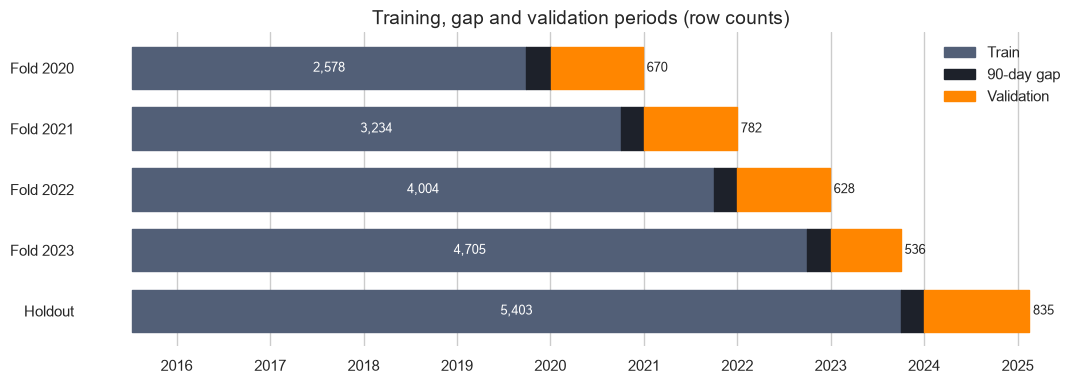

In [26]:
TRAIN_COLOUR, GAP_COLOUR, VAL_COLOUR = "#525f77", "#1d212a", "#ff8600"

plot_rows = [(f"Fold {y}", dev.iloc[tr], dev.iloc[va]) for (tr, va), y in zip(folds, VAL_YEARS)]
plot_rows.append(("Holdout", dev, holdout))

fig, ax = plt.subplots(figsize=(11, 4))

for i, (label, tr, va) in enumerate(plot_rows[::-1]):
    t0, t1 = mdates.date2num(tr["purchase_date"].min()), mdates.date2num(tr["purchase_date"].max())
    v0, v1 = mdates.date2num(va["purchase_date"].min()), mdates.date2num(va["purchase_date"].max())

    ax.broken_barh([(t0, t1 - t0)], (i - 0.35, 0.7), color=TRAIN_COLOUR)
    ax.broken_barh([(t1, v0 - t1)], (i - 0.35, 0.7), color=GAP_COLOUR)
    ax.broken_barh([(v0, v1 - v0)], (i - 0.35, 0.7), color=VAL_COLOUR)

    ax.text((t0 + t1) / 2, i, f"{len(tr):,}", ha="center", va="center", color="white", fontsize=9)
    ax.text(v1 + 15, i, f"{len(va):,}", ha="left", va="center", fontsize=9)

ax.set_yticks(range(len(plot_rows)))
ax.set_yticklabels([r[0] for r in plot_rows[::-1]])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
ax.set_title("Training, gap and validation periods (row counts)")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (TRAIN_COLOUR, GAP_COLOUR, VAL_COLOUR)]
ax.legend(handles, ["Train", "90-day gap", "Validation"], loc="upper right", frameon=False)

sns.despine(top=True, right=True, left=True, bottom=True)
plt.tight_layout()
plt.show()

## 3.2. How options are compared and how the threshold is chosen

The competition scores F1 on hard 0/1 predictions, and F1 depends on the cut-off that turns a probability into a class. A fixed cut-off of 0.5 would mix two questions: which option gives better probabilities, and where to cut. So each option gets its own cut-off.

- **Deciding between options:** F1 decides, since it is the competition metric. Each option is scored at its own best threshold, and the decision rule in section 5 checks whether a difference is larger than chance. Log-loss and ROC-AUC, which need no threshold, are reported alongside as a check.
- **Choosing the threshold:** the four validation years are stacked into one set of out-of-fold predictions, F1 is computed for every threshold from 0.05 to 0.95, and the threshold is taken from the middle of the flat region near the top rather than from a single sharp peak. A flat region holds up better when the share of positives moves.
- **Holdout:** scored once in `03_modelling.ipynb` with the threshold picked on the folds, never re-tuned on the holdout itself. Results there are also split into customers already seen in training and new customers.
- **Floor:** predicting 1 for everyone already gives a fair F1, equal to 2p / (1 + p) where p is the share of positives. A model that does not beat it is worse than doing nothing.

# 4. Reference model

Section 5 compares treatments for invalid values, missing values, outliers, scaling and encoding. Each comparison needs a fixed starting point, so this section sets up two reference models that every option is measured against:

- **Logistic regression** for the linear side. Scaling, transforms and outliers matter here.
- **Histogram gradient boosting** for the tree side. It handles missing values on its own and scaling is not needed, so it's used to test missing-value handling, encoding and features.

Both use the simplest reasonable preprocessing. They are a pre-baseline for this notebook, not the project's baseline, which is built in `03_modelling.ipynb`. Every model has to beat the all-positive floor from section 3.

Left out of the inputs: the keys (`ID`, `customer_id`), the purchase date, free-text or near-unique customer fields, and the repair flags. Later on we will test whether the flags help or should also be dropped.

In [27]:
EXCLUDE = ["ID", "customer_id", "purchase_date", target]

# Text columns and how many distinct values each has
text_cols = [
    c for c in dev.columns
    if c not in EXCLUDE and (pd.api.types.is_string_dtype(dev[c]) or dev[c].dtype == object)
]
text_card = pd.DataFrame({
    "distinct": dev[text_cols].nunique(),
    "share_distinct": dev[text_cols].nunique() / dev[text_cols].notna().sum(),
}).sort_values("distinct", ascending=False)
print("Text columns")
display(text_card)

# Numeric columns with few values: some may be codes rather than amounts
num_cols = [
    c for c in dev.select_dtypes("number").columns
    if c not in EXCLUDE and not c.startswith("flag_")
]
low_card = dev[num_cols].nunique()
print("Numeric columns with few distinct values")
display(low_card[low_card <= 15].sort_values().to_frame("distinct"))

Text columns


,distinct,share_distinct
company_name,569,0.105
address,560,0.104
postal_code,490,0.094
street,246,0.110
city,241,0.066
postal_area,183,0.035
municipality,145,0.028
transport_method,76,0.015
commercial_region,31,0.006
island,10,0.003


Numeric columns with few distinct values


,distinct
customer_type,0
invoice_count_current_purchase,5
customer_since_year,9
purchase_count_30d,12


Free-text and near-unique columns are dropped, because almost every value is different and a model could only memorise them. `customer_type` is dropped too, since it's empty in every row.

The other categorical columns are split by size. Columns with ten levels or fewer are one-hot encoded, and levels with fewer than 20 rows are grouped into one "rare" level. Larger columns would add hundreds of columns that way, so each is replaced by a single number: the share of training rows that have that level. Both encoders are fitted inside each training fold. Section 5.5 tests other options for the large columns.

In [28]:
FREE_TEXT = ["company_name", "address", "street", "postal_code"]
HIGH_CARD_LIMIT = 10  # more levels than this
RARE_MIN_ROWS = 20    # one-hot levels with fewer rows are grouped together

not_found = [c for c in FREE_TEXT if c not in dev.columns]
print("Names not found:", not_found)

# Columns with no values at all carry no information
empty_cols = [c for c in num_cols + text_cols if dev[c].isna().all()]
print("Empty columns dropped:", empty_cols)

num_features = [c for c in num_cols if c not in empty_cols]
cat_candidates = [c for c in text_cols if c not in FREE_TEXT + empty_cols]

# Split categories by number of levels
levels = dev[cat_candidates].nunique()
high_card = levels[levels > HIGH_CARD_LIMIT].index.tolist()
low_card = levels[levels <= HIGH_CARD_LIMIT].index.tolist()

features = num_features + high_card + low_card
print(f"Numeric: {len(num_features)} | Frequency-encoded: {len(high_card)} | One-hot: {len(low_card)}")
print("Frequency-encoded:", high_card)
print("One-hot:", low_card)


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each level with its share of training rows. Missing and unseen levels get 0."""

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.maps_ = {c: X[c].value_counts(normalize=True).to_dict() for c in self.columns_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return pd.DataFrame(
            {f"{c}_freq": X[c].map(self.maps_[c]).astype(float).fillna(0.0) for c in self.columns_},
            index=X.index,
        )

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_freq" for c in self.columns_])


def make_reference_models(num, high, low, num_steps=None, high_encoder="frequency"):
    """Both reference pipelines. num_steps replaces the numeric fill and scaling;
    high_encoder picks how the large categorical columns are encoded."""
    if num_steps is None:
        num_steps = [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]

    def high_block(scaled):
        # Encoders that turn a level into a number get scaled on the linear side
        if high_encoder == "frequency":
            enc = FrequencyEncoder()
        elif high_encoder == "target":
            enc = TargetEncoder(target_type="binary", random_state=RANDOM_STATE)
        elif high_encoder == "onehot_rare":
            return OneHotEncoder(
                handle_unknown="infrequent_if_exist", min_frequency=RARE_MIN_ROWS, sparse_output=False
            )
        else:
            raise ValueError(f"unknown high_encoder: {high_encoder!r}")
        return Pipeline([("encode", enc), ("scale", StandardScaler())]) if scaled else enc

    linear_prep = ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("high", high_block(scaled=True), high),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=RARE_MIN_ROWS), low),
    ], sparse_threshold=0)  # always return a dense matrix

    tree_prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), low),
        ("high", high_block(scaled=False), high),
        ("num", "passthrough", num),
    ], verbose_feature_names_out=False)

    return {
        "logistic": Pipeline([
            ("prep", linear_prep),
            ("model", LogisticRegression(max_iter=5000)),
        ]),
        "hist_gb": Pipeline([
            ("prep", tree_prep),
            ("model", HistGradientBoostingClassifier(
                categorical_features=list(range(len(low))),  # small categories come first
                random_state=RANDOM_STATE,
            )),
        ]),
    }

reference_models = make_reference_models(num_features, high_card, low_card)

log.record(
    "D15", ", ".join(empty_cols), "drop empty columns",
    "No value in any row, so the column carries no information.",
    len(train_clean), len(test_clean),
    carries={"drop": empty_cols},
)
log.record(
    "D16", "keys, date, free text, flags", "left out of the reference models",
    "Keys and date are not features; free text is near-unique; flags are tested in 5.1.",
    0, 0,
    carries={"drop": EXCLUDE + FREE_TEXT},
)
log.record(
    "D17", "categorical columns", f"one-hot if <= {HIGH_CARD_LIMIT} levels, frequency encoding above",
    "One-hot on every category would add about 700 columns for 5,403 rows.",
    0, 0,
    carries={"one_hot": low_card, "frequency": high_card, "min_frequency": RARE_MIN_ROWS},
)

display(log.to_frame().tail(3))

Names not found: []
Empty columns dropped: ['customer_type']
Numeric: 30 | Frequency-encoded: 5 | One-hot: 7
Frequency-encoded: ['transport_method', 'commercial_region', 'municipality', 'city', 'postal_area']
One-hot: ['payment_type', 'salesperson', 'commercial_zone', 'warehouse', 'document_series', 'country_or_region', 'island']


,step,column,action,reason,rows_train,rows_test
16,D15,customer_type,drop empty columns,"No value in any row, so the column carries no information.",6469,986
17,D16,"keys, date, free text, flags",left out of the reference models,Keys and date are not features; free text is near-unique; flags are tested in 5.1.,0,0
18,D17,categorical columns,"one-hot if <= 10 levels, frequency encoding above","One-hot on every category would add about 700 columns for 5,403 rows.",0,0


## 4.1. Scoring on the folds

Each model is fitted on the training part of every fold and scored on its validation year. Log-loss and ROC-AUC compare the probabilities without a threshold. For F1, the four validation years are stacked, one threshold is picked from the flat region near the top of the F1 curve, and that threshold is used on every fold.

Because the threshold is picked on the same rows it's scored on, the fold F1 values here are a little optimistic. The honest F1 comes from the holdout at the end.

Each fold's F1 is also compared with its own all-positive floor (`lift`), since the share of positives changes from year to year.

In [29]:
def best_threshold(y, p, tol=0.005):
    """Middle of the thresholds whose F1 is within tol of the best (grid 0.05 to 0.95)."""
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    y = np.asarray(y).astype(bool)[:, None]
    pred = np.asarray(p)[:, None] >= grid  # one column per threshold
    tp = (pred & y).sum(axis=0)
    fp = (pred & ~y).sum(axis=0)
    fn = (~pred & y).sum(axis=0)
    f1s = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    near_top = grid[f1s >= f1s.max() - tol]
    return float(np.median(near_top)), grid, f1s


def f1_floor(y):
    """F1 of predicting 1 for every row."""
    p = np.mean(y)
    return 2 * p / (1 + p)


def count_kept(model):
    """Columns that reach the final model, after encoding and selection."""
    if hasattr(model, "model_"):  # a model that picks its own columns wraps a fitted pipeline
        return count_kept(model.model_)
    steps = model.named_steps
    if "select" in steps:
        sel = steps["select"]
        if hasattr(sel, "n_components_"):  # PCA
            return int(sel.n_components_)
        return int(sel.get_support().sum())
    return len(steps["prep"].get_feature_names_out())


def score_folds(pipe, data, folds, features, train_filter=None):
    """Fit on each fold, return a per-fold table, the stacked predictions and the threshold.
    train_filter: optional function(train_part) -> boolean mask of training rows to keep."""
    rows, oof = [], []
    for (tr, va), year in zip(folds, VAL_YEARS):
        train_part, val_part = data.iloc[tr], data.iloc[va]
        if train_filter is not None:
            train_part = train_part[train_filter(train_part)]

        model = clone(pipe).fit(train_part[features], train_part[target])
        p = model.predict_proba(val_part[features])[:, 1]
        y = val_part[target].to_numpy()

        # Log-loss of always predicting the training positive rate
        ll = log_loss(y, p)
        ll_floor = log_loss(y, np.full(len(y), train_part[target].mean()))

        oof.append(pd.DataFrame({
            "fold": year, "y": y, "p": p,
            "customer_id": val_part["customer_id"].to_numpy(),  # used by the customer bootstrap
        }))
        rows.append({
            "fold": year, "train_rows": len(train_part), "n_features": count_kept(model),
            "log_loss": ll, "ll_floor": ll_floor, "ll_gain": ll_floor - ll,
            "roc_auc": roc_auc_score(y, p),
        })

    oof = pd.concat(oof, ignore_index=True)
    thr, _, _ = best_threshold(oof["y"], oof["p"])

    # F1 per fold at this model's own threshold
    for row in rows:
        part = oof[oof["fold"] == row["fold"]]
        row["f1"] = f1_score(part["y"], part["p"] >= thr)
        row["floor"] = f1_floor(part["y"])
        row["lift"] = row["f1"] - row["floor"]

    return pd.DataFrame(rows).set_index("fold"), oof, thr

In [30]:
results = {}
for name, pipe in reference_models.items():
    table, oof, thr = score_folds(pipe, dev, folds, features)
    results[name] = {"table": table, "oof": oof, "threshold": thr}

# Per-fold scores for both models
display(pd.concat({name: r["table"] for name, r in results.items()}))

# One line per model: fold averages, plus F1 on the four years stacked
summary = pd.DataFrame({
    name: {
        **r["table"].mean().to_dict(),
        "f1_stacked": f1_score(r["oof"]["y"], r["oof"]["p"] >= r["threshold"]),
        "threshold": r["threshold"],
    }
    for name, r in results.items()
}).T
display(summary[["log_loss", "ll_floor", "ll_gain", "roc_auc", "f1", "f1_stacked", "floor", "lift", "threshold"]])

train_rows  n_features  log_loss  ll_floor  ll_gain  roc_auc  \
         fold                                                                 
logistic 2020        2578          66     0.608     0.678    0.070    0.741   
         2021        3234          69     0.546     0.688    0.142    0.793   
         2022        4004          72     0.588     0.706    0.118    0.788   
         2023        4705          74     0.558     0.683    0.125    0.778   
hist_gb  2020        2578          42     0.658     0.678    0.019    0.727   
         2021        3234          42     0.551     0.688    0.137    0.794   
         2022        4004          42     0.599     0.706    0.107    0.774   
         2023        4705          42     0.615     0.683    0.068    0.761   

                 f1  floor   lift  
         fold                      
logistic 2020 0.752  0.745  0.007  
         2021 0.739  0.709  0.031  
         2022 0.691  0.649  0.041  
         2023 0.763  0.728  0.035  
hist_gb  2020 0.745  0.745 -0.001  
         2021 0.760  0.709  0.051  
         2022 0.702  0.649  0.052  
         2023 0.746  0.728  0.017

,log_loss,ll_floor,ll_gain,roc_auc,f1,f1_stacked,floor,lift,threshold
logistic,0.575,0.689,0.114,0.775,0.736,0.736,0.708,0.028,0.325
hist_gb,0.606,0.689,0.083,0.764,0.738,0.739,0.708,0.030,0.265


The curve shows how F1 changes with the threshold on the stacked validation years. A wide flat top means the choice of threshold matters less, which is what we want when the share of positives keeps moving.

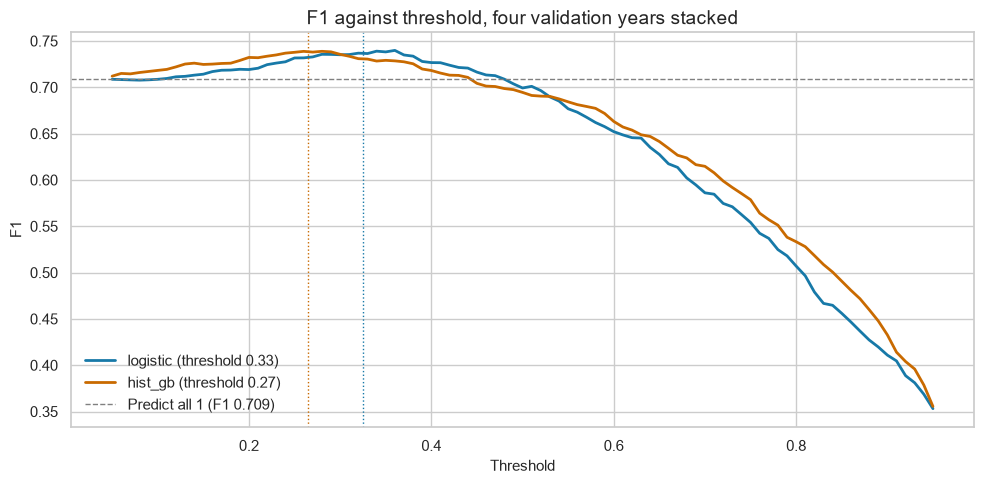

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
colours = {"logistic": "#1779A8", "hist_gb": "#C96A00"}

for name, r in results.items():
    _, grid, f1s = best_threshold(r["oof"]["y"], r["oof"]["p"])
    ax.plot(grid, f1s, color=colours[name], lw=2, label=f"{name} (threshold {r['threshold']:.2f})")
    ax.axvline(r["threshold"], color=colours[name], ls=":", lw=1)

floor = f1_floor(results["logistic"]["oof"]["y"])
ax.axhline(floor, color="grey", ls="--", lw=1, label=f"Predict all 1 (F1 {floor:.3f})")

ax.set_xlabel("Threshold")
ax.set_ylabel("F1")
ax.set_title("F1 against threshold, four validation years stacked")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Both models reach about the same best F1, close to 0.74, against 0.709 for predicting that every customer buys again. The gain over that simple rule is small, about 0.03. With more than half of the rows positive, predicting 1 for everyone already scores well on F1, so there is little room left above it.

The best thresholds are low: about 0.33 for logistic regression and 0.27 for gradient boosting. The top of both curves is flat, roughly from 0.25 to 0.50. Inside that range F1 barely moves, so the exact threshold matters less. 

Above 0.50 both curves fall steadily, down to about 0.35 at a threshold of 0.95. Gradient boosting falls more slowly in that region.

These fold scores are a little optimistic, because the threshold was picked on the same rows. The holdout gives the honest figure at the end.

# 5. Treatment comparisons

Each open preprocessing choice is tested here as a set of options, scored on the same four folds. Every step that learns from the data, such as a median or an encoder, is fitted inside the training part of each fold only.

Options are tested on the reference model that can actually react to them. Scaling, transforms and outliers make no difference to a tree, so those are tested on logistic regression only. Invalid values, encoding and customer fields are tested on both.

An option replaces the current reference only if all three hold:

1. Its F1 on the four validation years stacked is higher, with each option at its own best threshold.
2. The 95% bootstrap interval of the F1 difference excludes zero. The bootstrap resamples customers rather than rows, because rows from the same customer behave alike.
3. It is not worse than the reference in more than one of the four folds.

If an option is not clearly better, the reference stays. Log-loss, its gain over the floor and ROC-AUC are reported next to F1.

In [32]:
def fast_f1(y, pred):
    """F1 for boolean arrays, quicker than sklearn inside the bootstrap loop."""
    tp = np.sum(y & pred)
    fp = np.sum(~y & pred)
    fn = np.sum(y & ~pred)
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0


def bootstrap_f1_diff(oof_ref, oof_opt, thr_ref, thr_opt, n_boot=2000, seed=RANDOM_STATE):
    """95% interval of F1(option) - F1(reference), resampling whole customers."""
    assert (oof_ref["customer_id"].to_numpy() == oof_opt["customer_id"].to_numpy()).all()
    y = oof_ref["y"].to_numpy().astype(bool)
    pred_ref = oof_ref["p"].to_numpy() >= thr_ref
    pred_opt = oof_opt["p"].to_numpy() >= thr_opt

    # Row positions of each customer
    groups = list(oof_ref.groupby("customer_id").indices.values())
    rng = np.random.default_rng(seed)

    diffs = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        rows = np.concatenate([groups[i] for i in pick])
        diffs[b] = fast_f1(y[rows], pred_opt[rows]) - fast_f1(y[rows], pred_ref[rows])
    return np.percentile(diffs, [2.5, 97.5])


def judge(runs, reference, tie_rule=False):
    """Apply the decision rule to scored options.
    tie_rule=True (section 7): a tie goes to the option with fewer columns."""
    ref_table, ref_oof, ref_thr = runs[reference]
    ref_f1 = fast_f1(ref_oof["y"].to_numpy().astype(bool), ref_oof["p"].to_numpy() >= ref_thr)
    ref_n = ref_table["n_features"].mean()

    rows = []
    for name, (table, oof, thr) in runs.items():
        f1_all = fast_f1(oof["y"].to_numpy().astype(bool), oof["p"].to_numpy() >= thr)
        folds_worse = int((table["f1"] < ref_table["f1"]).sum())
        n = table["n_features"].mean()

        if name == reference:
            lo, hi, verdict = np.nan, np.nan, "reference"
        else:
            lo, hi = bootstrap_f1_diff(ref_oof, oof, ref_thr, thr)
            if lo > 0 and folds_worse <= 1:
                verdict = "better"
            elif hi < 0:
                verdict = "worse"
            elif tie_rule and n < ref_n and folds_worse <= 2:
                verdict = "tie, fewer columns"
            else:
                verdict = "no clear difference"

        rows.append({
            "option": name, "n_features": n, "f1_stacked": f1_all, "f1_diff": f1_all - ref_f1,
            "ci_low": lo, "ci_high": hi, "folds_worse": folds_worse, "threshold": thr,
            "log_loss": table["log_loss"].mean(), "ll_gain": table["ll_gain"].mean(),
            "roc_auc": table["roc_auc"].mean(), "verdict": verdict,
        })
    return pd.DataFrame(rows).set_index("option")


def compare_options(model_name, options, reference, folds):
    """Build each option's pipeline from the reference models, score it and apply the rule.
    Each option is a dict; any key left out takes the current setup."""
    runs = {}
    for name, spec in options.items():
        s = {
            "num": num_features, "extra_num": [], "high": high_card, "low": low_card,
            "num_steps": None, "train_filter": None, "high_encoder": "frequency", **spec,
        }
        num = s["num"] + s["extra_num"]
        pipe = make_reference_models(num, s["high"], s["low"], s["num_steps"], s["high_encoder"])[model_name]
        runs[name] = score_folds(pipe, s["data"], folds, num + s["high"] + s["low"], s["train_filter"])
    return judge(runs, reference), runs

## 5.1. Invalid values

Section 2.4 rebuilt the broken purchase-history values from the accounting identities. Rebuilding is one option among several, so it's tested against the alternatives:

- **keep:** the values as they were before the repair, errors included.
- **blank:** every value the repair changed becomes missing. Values the repair filled from missing stay missing.
- **blank_flag:** as blank, plus one column per repaired field marking the rows that were blanked.
- **rebuild:** the repaired data from section 2.4. This is the reference.
- **rebuild_flag:** the repaired data plus the repair flags from section 2.4.

The placeholders from 2.3 (-4 and one billion) are missing values in every option. They aren't real measurements, so keeping them isn't a fair option.

The rebuilt version is the reference because its rules were checked against the data in 2.4. The other options have to show they do better.

In [33]:
REPAIR_COLS = [
    "prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value",
    "spend_365d", "prior_mean_gap_days", "days_since_previous_purchase",
]
REPAIR_FLAGS = ["flag_mean_repaired", "flag_max_invalid", "flag_spend365_repaired", "flag_gap_rebuilt"]

def to_dev(df):
    return df[df["purchase_date"] < DEV_END].reset_index(drop=True)

# Data before the repair, same rows and order as dev
dev_keep = to_dev(train_pre_repair)
assert dev_keep["ID"].equals(dev["ID"]), "Row order differs between versions"

# Blank: values the repair changed become missing; values it filled stay missing
dev_blank = dev_keep.copy()
blank_flags = []
for col in REPAIR_COLS:
    before = dev_keep[col].to_numpy(dtype=float)
    after = dev[col].to_numpy(dtype=float)
    changed = ~np.isnan(before) & ~np.isclose(before, after, atol=TOL)
    print(f"{col:<32} blanked: {changed.sum()}")
    if changed.any():
        dev_blank.loc[changed, col] = np.nan
        flag = f"flag_{col}_blanked"
        dev_blank[flag] = changed.astype(int)
        blank_flags.append(flag)

options_51 = {
    "keep": {"data": dev_keep},
    "blank": {"data": dev_blank},
    "blank_flag": {"data": dev_blank, "extra_num": blank_flags},
    "rebuild": {"data": dev},
    "rebuild_flag": {"data": dev, "extra_num": REPAIR_FLAGS},
}

prior_mean_purchase_value        blanked: 47
prior_min_purchase_value         blanked: 0
prior_max_purchase_value         blanked: 41
spend_365d                       blanked: 52
prior_mean_gap_days              blanked: 0
days_since_previous_purchase     blanked: 0


In [34]:
results_51 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_51, "rebuild", folds)
    results_51[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep,70.250,0.736,-0.000,-0.006,0.005,3,0.330,0.578,0.110,0.773,no clear difference
blank,70.250,0.735,-0.001,-0.006,0.003,2,0.330,0.573,0.116,0.776,no clear difference
blank_flag,73.250,0.733,-0.003,-0.008,0.000,2,0.330,0.577,0.112,0.773,no clear difference
rebuild,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
rebuild_flag,74.250,0.738,0.002,-0.004,0.007,2,0.330,0.577,0.112,0.772,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep,42.000,0.729,-0.011,-0.020,-0.001,3,0.245,0.613,0.076,0.760,worse
blank,42.000,0.729,-0.010,-0.021,-0.000,2,0.285,0.612,0.077,0.763,worse
blank_flag,45.000,0.735,-0.005,-0.017,0.006,3,0.305,0.613,0.076,0.760,no clear difference
rebuild,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
rebuild_flag,46.000,0.730,-0.009,-0.018,-0.001,3,0.250,0.609,0.080,0.761,worse


Rebuilding the invalid values is kept. For logistic regression no option differs from it by more than 0.003 F1, and every bootstrap interval includes zero, so the linear model is not sensitive to how these values are treated. 

For gradient boosting, keeping the errors, blanking them and adding the repair flags all come out clearly worse than rebuilding, with intervals entirely below zero. Blanking with flags is not clearly different. Log-loss points the same way.

The repair flags do not improve either model, so they are not used. Rebuilding stays the treatment for invalid values, and the flag columns are left out of the inputs.

In [35]:
log.record(
    "D18", ", ".join(REPAIR_COLS), "keep rebuilt values, no repair flags",
    "Rebuild was never beaten; on gradient boosting keep, blank and rebuild with flags were clearly worse.",
    0, 0,
    carries={"invalid_values": "rebuild", "flags": False},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
19,D18,"prior_mean_purchase_value, prior_min_purchase_value, prior_max_purchase_value, spend_365d, prior...","keep rebuilt values, no repair flags","Rebuild was never beaten; on gradient boosting keep, blank and rebuild with flags were clearly w...",0,0


## 5.2. Missing values

After the repair, most missing values are structural rather than unknown. A customer making a first purchase has no mean purchase value, no largest purchase and no previous purchase date. A customer with one past purchase has no gap between purchases. A smaller group is missing for other reasons: maximums removed in the repair, a few interval values and some 365-day spends.

Five ways of filling the numeric columns are compared, on logistic regression only, since gradient boosting handles missing values by itself:

- **median:** the median of the training rows. This is the reference.
- **mean:** the mean of the training rows.
- **structural:** two columns mark first-time and single-purchase customers, structural gaps are filled with 0, and the remaining gaps use the median. With the marker present, the model can tell a 0 meaning "no history" from a real value.
- **knn:** each gap is filled from the five most similar rows. Columns are scaled before the fill, since distances depend on scale.
- **iterative:** each column with gaps is predicted from the other columns, repeated until the values settle.

Every fill is learned from the training part of each fold only. Categorical gaps are not part of this test. They stay as their own level.

In [36]:
HISTORY_COLS = [
    "prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value",
    "days_since_previous_purchase", "prior_mean_gap_days",
]
STRUCT_FLAGS = ["is_first_purchase", "is_single_purchase"]


def add_structural(df):
    """Mark first and single purchases and fill the gaps that only exist because of them."""
    df = df.copy()
    count = df["prior_purchase_count"]
    df["is_first_purchase"] = (count == 0).astype(int)
    df["is_single_purchase"] = (count == 1).astype(int)

    # No past purchase: no history values at all
    first = count == 0
    df.loc[first, HISTORY_COLS] = df.loc[first, HISTORY_COLS].fillna(0)

    # One past purchase: no gap between purchases
    single = count == 1
    df.loc[single, "prior_mean_gap_days"] = df.loc[single, "prior_mean_gap_days"].fillna(0)
    return df


dev_struct = add_structural(dev)
print("Missing before:", dev[HISTORY_COLS].isna().sum().to_dict())
print("Missing after: ", dev_struct[HISTORY_COLS].isna().sum().to_dict())

options_52 = {
    "median": {"data": dev, "num_steps": [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]},
    "mean": {"data": dev, "num_steps": [
        ("impute", SimpleImputer(strategy="mean")),
        ("scale", StandardScaler()),
    ]},
    "structural": {"data": dev_struct, "extra_num": STRUCT_FLAGS, "num_steps": [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]},
    "knn": {"data": dev, "num_steps": [
        ("scale", StandardScaler()),  # distances depend on scale, so scale first
        ("impute", KNNImputer(n_neighbors=5)),
    ]},
    "iterative": {"data": dev, "num_steps": [
        ("impute", IterativeImputer(max_iter=30, random_state=RANDOM_STATE)),
        ("scale", StandardScaler()),
    ]},
}

Missing before: {'prior_mean_purchase_value': 568, 'prior_min_purchase_value': 568, 'prior_max_purchase_value': 606, 'days_since_previous_purchase': 576, 'prior_mean_gap_days': 985}
Missing after:  {'prior_mean_purchase_value': 0, 'prior_min_purchase_value': 0, 'prior_max_purchase_value': 38, 'days_since_previous_purchase': 8, 'prior_mean_gap_days': 8}


In [37]:
table_52, runs_52 = compare_options("logistic", options_52, "median", folds)
display(table_52)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
median,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
mean,70.250,0.737,0.001,-0.003,0.006,2,0.340,0.575,0.114,0.775,no clear difference
structural,72.250,0.738,0.002,-0.001,0.006,2,0.325,0.577,0.112,0.774,no clear difference
knn,70.250,0.737,0.001,-0.004,0.006,2,0.320,0.576,0.113,0.775,no clear difference
iterative,70.250,0.735,-0.001,-0.005,0.003,2,0.320,0.576,0.113,0.774,no clear difference


None of the fills is clearly better than the median. Every option stays within 0.002 F1 of it, every bootstrap interval includes zero, and log-loss and ROC-AUC barely move. This is not surprising. Only a small share of cells is empty, and most of them belong to first-time buyers, who can also be recognised from `prior_purchase_count` and the zero values in the windowed counts and spends. Whatever goes into those cells changes few predictions. Marking first and single purchases explicitly does not add information the model doesn't already have.

The iterative imputer reached its limit of rounds before its values fully settled. Since every fill stayed within 0.002 F1 of the median, a longer run is unlikely to change the outcome.

The median fill is kept, since it is the simplest option and nothing beats it. The markers for first and single purchases are not added here. They could still help next to other history features, which is something to try during feature engineering.

In [38]:
log.record(
    "D19", "numeric columns", "fill missing values with the training median",
    "Mean, structural, KNN and iterative fills were not clearly better; median is the simplest.",
    0, 0,
    carries={"numeric_fill": "median"},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
20,D19,numeric columns,fill missing values with the training median,"Mean, structural, KNN and iterative fills were not clearly better; median is the simplest.",0,0


## 5.3. Outliers

Spend and count columns have long right tails: a few customers buy far more than the rest. Extreme values can pull a linear model's coefficients, so three treatments are compared on logistic regression. Trees only look at the order of values, so they are not affected.

- **keep:** values as they are. This is the reference.
- **winsorise:** values below the 1st or above the 99th percentile of the training rows are moved to those limits. The limits come from the raw training values, before the median fill, so the filled values don't shift them.
- **IQR drop:** training rows with any value more than 1.5 times the interquartile range beyond the quartiles are removed. Columns whose interquartile range is zero are skipped, since every non-zero value would count as extreme there. Validation rows are never removed.

The IQR drop is included on purpose as a negative control. It throws away real customers, so it should do worse. If the comparison could not show that, its other verdicts would not be worth much.

In [39]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to quantiles learned on the training rows. Missing values stay missing."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return input_features

def iqr_keep(train_part, k=1.5):
    """True for training rows with no value beyond the IQR fences."""
    X = train_part[num_features]
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    use = iqr[iqr > 0].index  # skip columns where the fences collapse
    outside = (X[use] < q1[use] - k * iqr[use]) | (X[use] > q3[use] + k * iqr[use])
    return ~outside.any(axis=1).to_numpy()


default_steps = [
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
]

options_53 = {
    "keep": {"data": dev, "num_steps": default_steps},
    "winsorise": {"data": dev, "num_steps": [
        ("clip", Winsorizer(0.01, 0.99)),  # limits from raw training values
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]},
    "iqr_drop": {"data": dev, "num_steps": default_steps, "train_filter": iqr_keep},
}

In [40]:
table_53, runs_53 = compare_options("logistic", options_53, "keep", folds)
display(table_53)

# How many training rows the IQR rule removed in each fold
kept = runs_53["iqr_drop"][0]["train_rows"]
full = runs_53["keep"][0]["train_rows"]
display(pd.DataFrame({"train_rows": full, "after_iqr": kept, "share_dropped": 1 - kept / full}))

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
winsorise,70.250,0.737,0.001,-0.005,0.007,2,0.340,0.572,0.116,0.770,no clear difference
iqr_drop,66.000,0.712,-0.024,-0.039,-0.009,4,0.275,0.845,-0.142,0.733,worse


,train_rows,after_iqr,share_dropped
fold,,,
2020,2578,1081,0.581
2021,3234,1275,0.606
2022,4004,1724,0.569
2023,4705,1987,0.578


Values are kept as they are. Winsorising at the 1st and 99th percentiles is not clearly different from keeping them: F1 moves by 0.001, the bootstrap interval includes zero, and log-loss and ROC-AUC point in opposite directions.

Dropping rows by the IQR rule is clearly worse. It removes close to 60% of the training rows in every fold, does worse on all four folds, and its log-loss ends up above the floor, so the model does worse than predicting the base rate. That is the expected result for a negative control, and it shows the comparison does pick up a harmful choice of this size. The many "no clear difference" results in this section therefore point to small effects rather than to a test that cannot see them.

In [41]:
log.record(
    "D20", "numeric columns", "keep outliers as they are",
    "Winsorising 1/99 was not clearly better; IQR drop (negative control) removed ~58% of rows and was clearly worse.",
    0, 0,
    carries={"outliers": "keep", "rule_tested": ["winsorize 1/99", "drop IQR 1.5"]},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
21,D20,numeric columns,keep outliers as they are,Winsorising 1/99 was not clearly better; IQR drop (negative control) removed ~58% of rows and wa...,0,0


## 5.4. Transformations and scaling

Logistic regression is sensitive to the scale and shape of its inputs, so five ways of preparing the numeric columns are compared. Trees only use the order of values, so they are not part of this test.

- **standard:** each column centred on its mean and divided by its standard deviation.
- **robust:** centred on the median and divided by the interquartile range, so extreme values have less pull.
- **minmax:** each column squeezed into the range 0 to 1.
- **log1p + standard:** right-skewed columns are log-transformed first, then standard scaling. The log compresses the long tail of large spenders. It only applies to columns with no negative values and a skewness above 1.
- **yeo-johnson:** each column is reshaped towards a bell curve with a strength learned from the training rows, then standardised. It works with zeros and negative values.

All of them are fitted inside each fold. The frequency-encoded columns keep standard scaling in every option, so only the effect on the numeric columns is measured.

In [42]:
# Right-skewed, non-negative columns for log1p (no target involved)
LOG_SKIP = ["random_noise", "customer_since_year"]
candidates = [c for c in num_features if c not in LOG_SKIP and dev[c].min() >= 0]
skew = dev[candidates].skew()
log_cols = skew[skew > 1].index.tolist()
print(f"log1p on {len(log_cols)} columns:")
display(skew[skew > 1].sort_values(ascending=False).to_frame("skewness"))


class Log1pColumns(BaseEstimator, TransformerMixin):
    """Apply log1p to the named columns and leave the rest untouched."""

    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        self.columns_in_ = list(X.columns)
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_in_).copy()
        cols = [c for c in self.columns if c in X.columns]
        X[cols] = np.log1p(X[cols].clip(lower=0))  # clip guards against a negative in new data
        return X

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_in_)


def median_then(scaler):
    return [("impute", SimpleImputer(strategy="median")), ("scale", scaler)]


options_54 = {
    "standard": {"data": dev, "num_steps": median_then(StandardScaler())},
    "robust": {"data": dev, "num_steps": median_then(RobustScaler())},
    "minmax": {"data": dev, "num_steps": median_then(MinMaxScaler())},
    "log1p_standard": {"data": dev, "num_steps": [
        ("log", Log1pColumns(log_cols)),
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]},
    "yeo_johnson": {"data": dev, "num_steps": [
        ("impute", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
    ]},
}

log1p on 27 columns:


,skewness
Total Desc_ Global,28.765
Total Portes,19.670
Total Desc_ Linha,6.722
invoice_count_current_purchase,6.359
prior_mean_gap_days,6.085
prior_min_purchase_value,5.802
days_since_previous_purchase,5.426
prior_std_gap_days,5.089
spend_30d,4.695
Custo,4.471


In [43]:
table_54, runs_54 = compare_options("logistic", options_54, "standard", folds)
display(table_54)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
standard,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
robust,70.250,0.738,0.002,-0.001,0.005,1,0.325,0.575,0.114,0.775,no clear difference
minmax,70.250,0.736,0.000,-0.010,0.009,1,0.365,0.570,0.118,0.770,no clear difference
log1p_standard,70.250,0.736,0.000,-0.009,0.009,3,0.350,0.566,0.123,0.773,no clear difference
yeo_johnson,70.250,0.740,0.004,-0.005,0.013,2,0.365,0.568,0.121,0.771,no clear difference


Standard scaling is kept. None of the options is clearly better on F1, and every bootstrap interval includes zero. For robust and min-max scaling this is expected: both only stretch and shift each column, and logistic regression can undo that through its coefficients. The small differences left come from the regularisation penalty, which depends on scale.

The log and Yeo-Johnson transforms change the shape of the columns, and they do improve log-loss, from 0.575 to 0.566 with log1p. The predicted probabilities get better for customers with very large values, but the ranking of customers hardly changes, so F1 and ROC-AUC stay put. Since F1 decides, the transform is not adopted here. It may still be worth trying with models that depend more on the shape of their inputs, such as an MLP or an SVM, if those are tried later.

In [44]:
log.record(
    "D21", "numeric columns", "standard scaling, no transform",
    "No option clearly better on F1. log1p improved log-loss (0.575 -> 0.566); flagged for retest in 03.",
    0, 0,
    carries={"scaler": "standard", "transform": "none", "log1p_candidates": log_cols},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
22,D21,numeric columns,"standard scaling, no transform",No option clearly better on F1. log1p improved log-loss (0.575 -> 0.566); flagged for retest in 03.,0,0


## 5.5. Encoding the large categorical columns

Five categorical columns have more than ten levels: `transport_method`, `commercial_region`, `municipality`, `city` and `postal_area`. One-hot encoding them all would add hundreds of columns, so four alternatives are compared on both reference models:

- **frequency:** each level is replaced by its share of training rows. This is the reference.
- **target:** each level is replaced by the share of repeat purchases among its training rows. The encoder splits the training part internally, so a row's own label is not used to encode it. That split is by row rather than by customer, though, so a customer with many purchases can sit on both sides of it, and the encoded value may partly reflect that customer's own labels.
- **rare + one-hot:** one column per level, with levels under 20 rows grouped together.
- **coarse geography:** `city`, `postal_area` and `municipality` are dropped. They describe location in more detail than `commercial_region` and `island`, which stay. `commercial_region` and `transport_method` keep frequency encoding.

The seven small categorical columns are encoded the same way in every option.

In [45]:
COARSE_DROP = ["city", "postal_area", "municipality"]
coarse_high = [c for c in high_card if c not in COARSE_DROP]
print("Coarse geography keeps:", coarse_high)

options_55 = {
    "frequency": {"data": dev},
    "target": {"data": dev, "high_encoder": "target"},
    "onehot_rare": {"data": dev, "high_encoder": "onehot_rare"},
    "coarse_geo": {"data": dev, "high": coarse_high},
}

results_55 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_55, "frequency", folds)
    results_55[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)

Coarse geography keeps: ['transport_method', 'commercial_region']


d:\Irshad\NOVA\Masters Business Analytics\Machine Learning\ML_Project\ml-repeat-purchase\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
d:\Irshad\NOVA\Masters Business Analytics\Machine Learning\ML_Project\ml-repeat-purchase\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
d:\Irshad\NOVA\Masters Business Analytics\Machine Learning\ML_Project\ml-repeat-purchase\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `Targe


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
frequency,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
target,70.250,0.735,-0.001,-0.010,0.007,3,0.325,0.571,0.118,0.776,no clear difference
onehot_rare,203.250,0.732,-0.004,-0.015,0.010,3,0.275,0.593,0.096,0.759,no clear difference
coarse_geo,67.250,0.739,0.003,-0.003,0.010,2,0.310,0.573,0.116,0.777,no clear difference


d:\Irshad\NOVA\Masters Business Analytics\Machine Learning\ML_Project\ml-repeat-purchase\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
d:\Irshad\NOVA\Masters Business Analytics\Machine Learning\ML_Project\ml-repeat-purchase\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
d:\Irshad\NOVA\Masters Business Analytics\Machine Learning\ML_Project\ml-repeat-purchase\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `Targe


hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
frequency,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
target,42.000,0.734,-0.005,-0.017,0.005,3,0.290,0.604,0.085,0.764,no clear difference
onehot_rare,175.000,0.734,-0.005,-0.017,0.007,3,0.280,0.608,0.081,0.758,no clear difference
coarse_geo,39.000,0.735,-0.004,-0.018,0.008,2,0.340,0.596,0.093,0.767,no clear difference


Frequency encoding is kept. No option is clearly better on either model. One-hot encoding with rare levels grouped does worst for logistic regression, with clearly higher log-loss, which fits the idea that too many sparse columns hurt with this amount of data. Target encoding is close to the reference on both models.

Keeping only the coarse geography is never worse. It gives the best log-loss and ROC-AUC on both models while using three fewer columns, which suggests `city`, `postal_area` and `municipality` add little beyond `commercial_region` and `island`. Dropping columns is a selection question, so this stays an option to try when columns are selected.

Across sections 5.1 to 5.5 the pattern is consistent: preprocessing choices move F1 by less than 0.005, below what the bootstrap can separate, while the negative control in 5.3 showed that a harmful choice does get caught. The models are robust to these choices. Most of their signal comes from the purchase-history columns, so further gains are more likely to come from new features than from more preprocessing.

In [46]:
log.record(
    "D22", ", ".join(high_card), "keep frequency encoding",
    "No option clearly better on either model; coarse geography never worse, drop decision moved to section 7.",
    0, 0,
    carries={"high_card_encoding": "frequency", "coarse_geo_candidate_drop": COARSE_DROP},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
23,D22,"transport_method, commercial_region, municipality, city, postal_area",keep frequency encoding,"No option clearly better on either model; coarse geography never worse, drop decision moved to s...",0,0


## 5.6. Customer-table fields

The customer table adds where each customer is located and the year they became a customer. The previous section suggested that the finer geography adds little. This section asks the broader question: does the customer table help at all, on top of the purchase data? Three versions are compared on both reference models:

- **all:** purchase columns plus every customer field. This is the reference.
- **no customer table:** purchase columns only.
- **since year only:** purchase columns plus `customer_since_year`, the one customer field that isn't about location.

In [47]:
# Columns that came from the customer table
customer_fields = [c for c in clientes.columns if c != "customer_id"]

num_purchase = [c for c in num_features if c not in customer_fields]
high_purchase = [c for c in high_card if c not in customer_fields]
low_purchase = [c for c in low_card if c not in customer_fields]

print("Customer fields in use:", [c for c in features if c in customer_fields])
print("Purchase-only inputs:", len(num_purchase), "numeric,", len(high_purchase), "large and",
      len(low_purchase), "small categorical")

options_56 = {
    "all": {"data": dev},
    "no_customer_table": {"data": dev, "num": num_purchase, "high": high_purchase, "low": low_purchase},
    "since_year_only": {
        "data": dev, "num": num_purchase + ["customer_since_year"],
        "high": high_purchase, "low": low_purchase,
    },
}

results_56 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_56, "all", folds)
    results_56[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)

Customer fields in use: ['customer_since_year', 'commercial_region', 'municipality', 'city', 'postal_area', 'country_or_region', 'island']
Purchase-only inputs: 29 numeric, 1 large and 5 small categorical

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
all,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
no_customer_table,51.750,0.730,-0.006,-0.014,0.004,3,0.340,0.576,0.112,0.769,no clear difference
since_year_only,52.750,0.736,0.000,-0.007,0.009,2,0.320,0.576,0.113,0.773,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
all,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
no_customer_table,35.000,0.720,-0.019,-0.031,-0.008,4,0.295,0.622,0.066,0.747,worse
since_year_only,36.000,0.730,-0.010,-0.024,0.003,4,0.325,0.611,0.078,0.758,no clear difference


The customer table is kept. For gradient boosting, removing it is clearly worse: F1 drops by 0.019, the bootstrap interval stays below zero, and every fold gets worse. Keeping only `customer_since_year` loses most of that, so the value comes mainly from the location fields. For logistic regression the difference is not clear, but it points the same way, with lower ROC-AUC and three of four folds worse without the table.

Together with 5.5, location seems to help at the coarse level, region and island, more than through city, postal area or municipality. Gradient boosting likely benefits more because it can combine location with purchase history on its own.

In [48]:
log.record(
    "D23", ", ".join(customer_fields), "keep customer-table fields",
    "Without them gradient boosting is clearly worse (F1 -0.019, worse in all folds); location carries most of it.",
    0, 0,
    carries={"customer_table": "keep"},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
24,D23,"country_or_region, commercial_region, island, municipality, city, postal_area, postal_code, stre...",keep customer-table fields,"Without them gradient boosting is clearly worse (F1 -0.019, worse in all folds); location carrie...",0,0


## 5.7. Summary of treatment decisions

| Step | Decision | Evidence |
|---|---|---|
| 5.1 Invalid values | Rebuild from the identities, no repair flags | Never beaten; on gradient boosting the alternatives were clearly worse |
| 5.2 Missing values | Median fill | No fill clearly better on logistic regression |
| 5.3 Outliers | Keep as they are | Winsorising not clearly better; IQR drop clearly worse (negative control) |
| 5.4 Scaling | Standard, no transform | Linear rescalings can't change logistic regression; log1p improved log-loss only |
| 5.5 Large categories | Frequency encoding | No option clearly better; coarse geography never worse, kept as an option for selection |
| 5.6 Customer table | Keep | Clearly worse without it on gradient boosting |

# 6. Feature engineering

The purchase-history columns hold most of the signal, but several of them only make sense relative to each other. A 60-day gap means something different for a customer who buys every month than for one who buys twice a year. This section builds new features from the existing columns and tests whether they help.

## 6.1. Ratio and marker features

New features are built as ratios between existing columns, in five groups:

- **A. Recency against habit:** days since the previous purchase divided by the customer's mean gap. Above 1 means the customer is later than usual; below 1, earlier.
- **B. Purchase rates:** purchases per year of tenure, and the share of the last year's purchases made in the last 90 days.
- **C. Spend trend:** the share of the last year's spend made in the last 90 days, and the share of lifetime spend made in the last 180 days. Rising shares mean spending is speeding up.
- **D. Current basket against history:** the value of the current purchase divided by the customer's mean past purchase.
- **E. History markers:** whether this is the customer's first or second purchase.

Every feature uses only the values on its own row, so nothing from later purchases leaks in. When a denominator is zero, the ratio is left missing and filled by the training median inside each fold.

Each group is added on its own to the current setup and compared on both reference models, with the same decision rule as in section 5. A last option adds all five groups together.

In [49]:
def safe_ratio(num, den):
    """num / den, missing where the denominator is zero, negative or missing."""
    return num / den.where(den > 0)


# Each feature: group, name, columns it needs, how it's built
FEATURE_SPECS = [
    ("A", "recency_vs_habit", ["days_since_previous_purchase", "prior_mean_gap_days"],
     lambda d: safe_ratio(d["days_since_previous_purchase"], d["prior_mean_gap_days"])),
    ("B", "purchases_per_year", ["prior_purchase_count", "customer_tenure_days"],
     lambda d: safe_ratio(d["prior_purchase_count"], d["customer_tenure_days"] / 365.25)),
    ("B", "recent_activity_share", ["purchase_count_90d", "purchase_count_365d"],
     lambda d: safe_ratio(d["purchase_count_90d"], d["purchase_count_365d"])),
    ("C", "spend_share_90_365", ["spend_90d", "spend_365d"],
     lambda d: safe_ratio(d["spend_90d"], d["spend_365d"])),
    ("C", "spend_share_180_total", ["spend_180d", "prior_total_spend"],
     lambda d: safe_ratio(d["spend_180d"], d["prior_total_spend"])),
    ("D", "basket_vs_mean", ["Total Liquido", "prior_mean_purchase_value"],
     lambda d: safe_ratio(d["Total Liquido"], d["prior_mean_purchase_value"])),
    ("E", "is_first_purchase", ["prior_purchase_count"],
     lambda d: (d["prior_purchase_count"] == 0).astype(int)),
    ("E", "is_single_purchase", ["prior_purchase_count"],
     lambda d: (d["prior_purchase_count"] == 1).astype(int)),
]

def add_features(df):
    """Add every feature whose source columns exist. Row by row, nothing is learned."""
    df = df.copy()
    built = {}
    for group, name, needs, build in FEATURE_SPECS:
        missing = [c for c in needs if c not in df.columns]
        if missing:
            print(f"Skipped {name}: missing {missing}")
            continue
        df[name] = build(df)
        built.setdefault(group, []).append(name)
    return df, built

dev_fe, feature_groups = add_features(dev)
new_features = [f for names in feature_groups.values() for f in names]

# Check how often each feature is missing and its range
display(pd.DataFrame({
    "group": {f: g for g, names in feature_groups.items() for f in names},
    "missing_share": dev_fe[new_features].isna().mean(),
    "median": dev_fe[new_features].median(),
    "p99": dev_fe[new_features].quantile(0.99),
    "max": dev_fe[new_features].max(),
}))

,group,missing_share,median,p99,max
recency_vs_habit,A,0.182,0.847,12.071,478.667
purchases_per_year,B,0.105,5.277,61.601,365.250
recent_activity_share,B,0.142,0.200,1.000,1.000
spend_share_90_365,C,0.163,0.155,1.000,1.000
spend_share_180_total,C,0.105,0.168,1.000,1.000
basket_vs_mean,D,0.105,0.665,5.628,30.997
is_first_purchase,E,0.000,0.000,1.000,1.000
is_single_purchase,E,0.000,0.000,1.000,1.000


In [50]:
# Baseline uses dev_fe too, so every option sees exactly the same rows
options_6 = {"base": {"data": dev_fe}}
for group, names in feature_groups.items():
    options_6[f"group_{group}"] = {"data": dev_fe, "extra_num": names}
options_6["all_groups"] = {"data": dev_fe, "extra_num": new_features}

results_6 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_6, "base", folds)
    results_6[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,70.250,0.736,0.000,NaN,NaN,0,0.325,0.575,0.114,0.775,reference
group_A,71.250,0.739,0.003,-0.000,0.007,1,0.330,0.574,0.114,0.774,no clear difference
group_B,72.250,0.738,0.002,-0.004,0.007,1,0.340,0.576,0.113,0.774,no clear difference
group_C,72.250,0.739,0.003,-0.003,0.009,1,0.335,0.575,0.113,0.774,no clear difference
group_D,71.250,0.735,-0.001,-0.003,0.001,2,0.325,0.575,0.114,0.775,no clear difference
group_E,72.250,0.741,0.005,0.001,0.009,1,0.330,0.576,0.113,0.774,better
all_groups,78.250,0.735,-0.001,-0.007,0.005,2,0.330,0.576,0.112,0.772,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
group_A,43.000,0.734,-0.005,-0.015,0.004,4,0.290,0.606,0.083,0.763,no clear difference
group_B,44.000,0.731,-0.008,-0.021,0.002,4,0.310,0.607,0.081,0.765,no clear difference
group_C,44.000,0.722,-0.018,-0.029,-0.008,4,0.250,0.619,0.070,0.757,worse
group_D,43.000,0.736,-0.003,-0.014,0.006,3,0.280,0.606,0.083,0.767,no clear difference
group_E,44.000,0.738,-0.001,-0.009,0.005,3,0.295,0.611,0.078,0.763,no clear difference
all_groups,50.000,0.731,-0.008,-0.022,0.003,3,0.330,0.609,0.080,0.766,no clear difference


For logistic regression, the markers for first and single purchases (group E) pass the decision rule: F1 rises by 0.005, the bootstrap interval stays just above zero, and only one fold gets worse. Log-loss and ROC-AUC barely move. The gain has a plausible reason: a linear model cannot draw a jump at zero past purchases from the count column alone, and the markers give it that jump. Still, the interval only just clears zero and six groups were tested, so the gain is small and may not hold up.

For gradient boosting no group helps. The spend-trend ratios (group C) are clearly worse, and the other groups are worse in three or four folds without being clear. With default settings and about 5,000 training rows, extra columns seem to add more noise than signal for the trees, which can also approximate most of these ratios by splitting on the original columns.

The linear branch therefore adds group E, and the tree branch keeps its inputs unchanged.

In [51]:
group_E = feature_groups["E"]

log.record(
    "D24", ", ".join(group_E), "add for the linear branch only",
    "Group E passed the rule on logistic (F1 +0.005, CI 0.001 to 0.009); no group helped gradient boosting, group C was clearly worse.",
    0, 0,
    carries={"linear_extra": group_E, "tree_extra": []},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
25,D24,"is_first_purchase, is_single_purchase",add for the linear branch only,"Group E passed the rule on logistic (F1 +0.005, CI 0.001 to 0.009); no group helped gradient boo...",0,0


## 6.2. Calendar features and the start year

The time of year may matter. A purchase made in October has its 90-day window over the year end, while one made in June does not. Many customers look like companies, so the day of the week may also reflect ordering routines. Two groups are tested:

- **F. Month**
- **G. Day of week**

For logistic regression each is written as the sine and cosine of its position on a circle, so December sits next to January and Sunday next to Monday, the way a clock puts 23:00 next to 01:00. Gradient boosting gets the plain month and weekday numbers, since it can split them wherever it needs.

The purchase year is left out on purpose. The test set covers 2025 and 2026, later than any training year, so the model would have to guess at values it has never seen. And because the share of repeat purchases drifts over time, the year mostly carries that drift rather than a pattern that holds. A similar concern applies to `customer_since_year`, which is looked at the end of this section.

In [52]:
def add_calendar(df):
    """Month and weekday as numbers and as positions on a circle, plus years as a customer."""
    df = df.copy()
    month = df["purchase_date"].dt.month
    dow = df["purchase_date"].dt.dayofweek  # Monday = 0
    df["month"] = month
    df["day_of_week"] = dow
    df["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    df["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
    df["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    df["dow_cos"] = np.cos(2 * np.pi * dow / 7)

    # Relative version of the start year: how long the customer had been a customer at this purchase
    df["years_as_customer"] = df["purchase_date"].dt.year - df["customer_since_year"]
    return df


dev_cal = add_calendar(dev_fe)

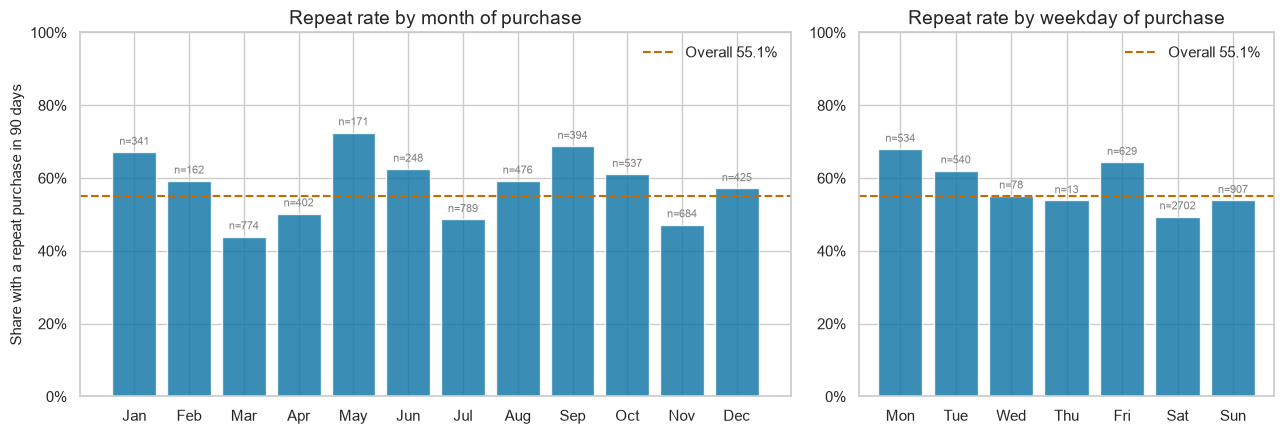

In [53]:
# Repeat rate and number of purchases by month and by weekday
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [12, 7]})
overall = dev_cal[target].mean()

for ax, col, labels in [
    (axes[0], "month", ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]),
    (axes[1], "day_of_week", ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]),
]:
    stats_by = dev_cal.groupby(col)[target].agg(["mean", "size"]).reindex(range(dev_cal[col].min(), dev_cal[col].max() + 1))
    x = np.arange(len(stats_by))
    ax.bar(x, stats_by["mean"], color="#1779A8", alpha=0.85)
    ax.axhline(overall, color="#C96A00", ls="--", lw=1.5, label=f"Overall {overall:.1%}")
    ax.set_xticks(x)
    ax.set_xticklabels(labels[: len(stats_by)] if col == "month" else [labels[i] for i in stats_by.index])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for xi, (rate, n) in enumerate(zip(stats_by["mean"], stats_by["size"])):
        if pd.notna(rate):
            ax.text(xi, rate + 0.02, f"n={int(n)}", ha="center", fontsize=8, color="grey")
    ax.legend(frameon=False, loc="upper right")

axes[0].set_title("Repeat rate by month of purchase")
axes[1].set_title("Repeat rate by weekday of purchase")
axes[0].set_ylabel("Share with a repeat purchase in 90 days")
plt.tight_layout()
plt.show()

In [54]:
CAL_LINEAR = {"F": ["month_sin", "month_cos"], "G": ["dow_sin", "dow_cos"]}
CAL_TREE = {"F": ["month"], "G": ["day_of_week"]}

# Linear branch: reference already includes group E
options_62_linear = {"base_E": {"data": dev_cal, "extra_num": group_E}}
for g, cols in CAL_LINEAR.items():
    options_62_linear[f"E_plus_{g}"] = {"data": dev_cal, "extra_num": group_E + cols}

# Tree branch: reference has no extra features
options_62_tree = {"base": {"data": dev_cal}}
for g, cols in CAL_TREE.items():
    options_62_tree[f"group_{g}"] = {"data": dev_cal, "extra_num": cols}

table_62_lin, runs_62_lin = compare_options("logistic", options_62_linear, "base_E", folds)
print("logistic")
display(table_62_lin)

table_62_tree, runs_62_tree = compare_options("hist_gb", options_62_tree, "base", folds)
print("\nhist_gb")
display(table_62_tree)

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base_E,72.250,0.741,0.000,NaN,NaN,0,0.330,0.576,0.113,0.774,reference
E_plus_F,74.250,0.736,-0.005,-0.014,0.003,2,0.290,0.580,0.108,0.771,no clear difference
E_plus_G,74.250,0.741,0.000,-0.003,0.003,1,0.330,0.576,0.113,0.774,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
group_F,43.000,0.735,-0.004,-0.017,0.007,3,0.310,0.605,0.084,0.769,no clear difference
group_G,43.000,0.730,-0.010,-0.019,-0.000,3,0.295,0.606,0.083,0.764,worse


Neither calendar feature is kept. For logistic regression, month and weekday leave F1 unchanged or slightly lower. For gradient boosting, month makes no clear difference, and weekday is clearly worse.

The chart shows large differences in repeat rate by month, from about 43% in March to about 72% in May. The model still gains nothing from the month, because those differences mostly reflect which customers buy at which time of year, and the model already knows each customer's history. A variable can look strong on its own and add nothing once the history is known.

The weekday chart shows something unusual: about half of all purchases fall on a Saturday, and very few on Wednesday or Thursday. For customers that look like companies, this suggests `purchase_date` may record a batch or posting date rather than the day the order was placed. That would also explain why the weekday hurt gradient boosting, which fitted a pattern in how dates were recorded.

In [55]:
log.record(
    "D25", "month, day_of_week", "no calendar features",
    "Month not clearly better on either model; weekday clearly worse on gradient boosting. Weekday distribution suggests batch or posting dates.",
    0, 0,
    carries={"calendar": False, "year_excluded": "outside training range, carries drift"},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
26,D25,"month, day_of_week",no calendar features,Month not clearly better on either model; weekday clearly worse on gradient boosting. Weekday di...,0,0


**Start year.** Section 2.5 found 41 test rows whose customers started in 2025 or 2026, after the last start year in training. The folds show the same problem on a smaller scale: in each validation year, customers who joined that year have a start year the training part never saw. Three versions are compared on both reference models:

- **since_year:** `customer_since_year` as it is. This is the reference.
- **years_as_customer:** replaced by the purchase year minus the start year. New customers get small values, which training has plenty of.
- **drop:** no start-year information at all.

The relative version narrows the problem but does not remove it. The longest-standing customers in test have been customers for a little longer than anyone in training, the same issue `customer_tenure_days` already has. The cell below prints both ranges.

Unlike the other tests, a tie here goes to `years_as_customer`. It carries the same information while reducing a known problem in the test set, which the folds can only partly show. It is rejected only if it is clearly worse.

In [56]:
SINCE = "customer_since_year"

# Ranges: the relative version should stay closer to what training has seen
test_years = test_clean["purchase_date"].dt.year - test_clean[SINCE]
print(f"customer_since_year  dev: {dev_cal[SINCE].min()} to {dev_cal[SINCE].max()} | "
      f"test: {test_clean[SINCE].min()} to {test_clean[SINCE].max()}")
print(f"years_as_customer    dev: {dev_cal['years_as_customer'].min()} to {dev_cal['years_as_customer'].max()} | "
      f"test: {test_years.min()} to {test_years.max()}")

num_relative = [c for c in num_features if c != SINCE] + ["years_as_customer"]
num_without = [c for c in num_features if c != SINCE]

# Linear branch keeps group E; tree branch has no extra columns
options_since_lin = {
    "since_year": {"data": dev_cal, "extra_num": group_E},
    "years_as_customer": {"data": dev_cal, "num": num_relative, "extra_num": group_E},
    "drop": {"data": dev_cal, "num": num_without, "extra_num": group_E},
}
options_since_tree = {
    "since_year": {"data": dev_cal},
    "years_as_customer": {"data": dev_cal, "num": num_relative},
    "drop": {"data": dev_cal, "num": num_without},
}

table_since_lin, runs_since_lin = compare_options("logistic", options_since_lin, "since_year", folds)
print("\nlogistic")
display(table_since_lin)

table_since_tree, runs_since_tree = compare_options("hist_gb", options_since_tree, "since_year", folds)
print("\nhist_gb")
display(table_since_tree)

customer_since_year  dev: 2015 to 2023 | test: 2015 to 2026
years_as_customer    dev: 0 to 8 | test: 0 to 11

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
since_year,72.250,0.741,0.000,NaN,NaN,0,0.330,0.576,0.113,0.774,reference
years_as_customer,72.250,0.738,-0.003,-0.010,0.005,4,0.330,0.579,0.110,0.769,no clear difference
drop,71.250,0.740,-0.001,-0.007,0.005,2,0.335,0.578,0.111,0.770,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
since_year,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
years_as_customer,42.000,0.728,-0.011,-0.022,-0.001,3,0.255,0.610,0.079,0.760,worse
drop,41.000,0.728,-0.011,-0.021,-0.001,3,0.240,0.614,0.075,0.755,worse


For gradient boosting, the start year is clearly worth keeping. Replacing it with the years as a customer, or dropping it, both lower F1 by about 0.011, with intervals below zero. A tree also copes with later start years on its own: any year after the last one in training falls on the same side of every split as that last year, so new customers are treated like the newest cohort the model has seen.

For logistic regression the rule written above would pick the relative version, since it is not clearly worse. But it is worse in all four folds, and log-loss and ROC-AUC drop too, so adopting it would follow the wording of the rule against what the folds show. The absolute start year seems to carry a cohort effect, customers who joined in different years behaving differently, which the relative version loses. A different fix is tried instead: keep the start year, and clip every numeric column to the range seen in its training part. That stops a linear model from extending its line beyond the data, which is what a tree does anyway, and it also covers the tenure and spend values that run longer in the test set.

In [57]:
# Clip each numeric column to the training range (min to max) before the fill
range_guard_steps = [
    ("clip", Winsorizer(0.0, 1.0)),  # 0th and 100th percentiles of the training part
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
]

options_guard = {
    "since_year": {"data": dev_cal, "extra_num": group_E},
    "since_year_clipped": {"data": dev_cal, "extra_num": group_E, "num_steps": range_guard_steps},
}

table_guard, runs_guard = compare_options("logistic", options_guard, "since_year", folds)
display(table_guard)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
since_year,72.250,0.741,0.000,NaN,NaN,0,0.330,0.576,0.113,0.774,reference
since_year_clipped,72.250,0.740,-0.001,-0.004,0.004,3,0.335,0.575,0.114,0.773,no clear difference


Clipping to the training range does not pass either. F1 is 0.001 lower, with an interval that includes zero, but it is worse in three of the four folds, one more than the rule allows.

`customer_since_year` is therefore kept as it is in both branches. Every alternative was clearly worse for gradient boosting, and for logistic regression none passed the rule. A small known risk remains: for the 4.2% of test rows whose customers started after 2024, a linear model has to extend its line beyond the data, while a tree treats them like the newest cohort it has seen. That is worth keeping in mind if a linear model ends up being the final choice.

In [58]:
log.record(
    "D26", "customer_since_year", "keep as it is in both branches",
    "Years as a customer and dropping were clearly worse for gradient boosting; for logistic, the relative "
    "version was worse in all four folds and clipping to the training range in three. "
    "41 test rows (4.2%) start after 2024.",
    0, 0,
    carries={"customer_since_year": "keep", "tested": ["years_as_customer", "drop", "clip to training range"]},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
27,D26,customer_since_year,keep as it is in both branches,"Years as a customer and dropping were clearly worse for gradient boosting; for logistic, the rel...",0,0


## 6.3. The customer's past repeat rate

Most purchases come from customers who already have a history, and part of that history has known outcomes: for an earlier purchase whose 90-day window has closed, we know whether the customer came back in time. The share of those earlier purchases that were followed by a repeat is information the current columns don't contain. They describe how often and how much a customer bought, not how often a purchase led to another one within 90 days.

Two rules keep this honest:

- **Only closed windows count.** An earlier purchase is used only if it happened more than 90 days before the current one, so its outcome was already known.
- **Only labels the model could have.** For the test set, the only known outcomes come from the training data, since test purchases have no labels. To copy that, the feature is computed inside each fold from the training part only. Training rows use earlier training rows, and validation rows use training rows only, never other validation rows. It works like a target encoder, per customer and in time order.

The model gets two columns: the past repeat rate, missing when there is no earlier closed purchase, and the number of earlier purchases it is based on, so a rate built on one purchase is not read like one built on twenty.

The data seems to hold only some of each customer's purchases, so many rows may have no earlier labelled purchase at all. Coverage is checked first.

In [59]:
PAST_KEYS = ["customer_id", "purchase_date"]

def build_history(customers, dates, labels):
    """Per customer: sorted purchase dates and the running count of repeats."""
    hist = pd.DataFrame({
        "customer_id": np.asarray(customers),
        "date": pd.to_datetime(np.asarray(dates)).to_numpy(dtype="datetime64[ns]"),
        "y": np.asarray(labels).astype(int),
    }).sort_values(["customer_id", "date"])
    return {
        c: (g["date"].to_numpy(), np.concatenate([[0], np.cumsum(g["y"].to_numpy())]))
        for c, g in hist.groupby("customer_id")
    }

def past_counts(history, customers, dates):
    """For each row: earlier purchases with a closed 90-day window, and how many were repeats."""
    cutoff = (pd.to_datetime(np.asarray(dates)) - pd.Timedelta(days=GAP_DAYS)).to_numpy(dtype="datetime64[ns]")
    count = np.zeros(len(cutoff))
    repeats = np.zeros(len(cutoff))
    for i, (c, t) in enumerate(zip(np.asarray(customers), cutoff)):
        if c in history:
            past_dates, cum = history[c]
            k = np.searchsorted(past_dates, t, side="left")  # purchases dated before the cutoff
            count[i], repeats[i] = k, cum[k]
    return count, repeats

class PastRepeatRate(BaseEstimator, TransformerMixin):
    """Remember the training labels; give each row the repeat rate of its customer's closed past purchases."""

    def fit(self, X, y):
        self.history_ = build_history(X["customer_id"], X["purchase_date"], y)
        return self

    def transform(self, X):
        count, repeats = past_counts(self.history_, X["customer_id"], X["purchase_date"])
        rate = np.where(count > 0, repeats / np.maximum(count, 1), np.nan)
        return pd.DataFrame({"past_repeat_rate": rate, "past_labelled_count": count}, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array(["past_repeat_rate", "past_labelled_count"])

In [60]:
# Coverage only, no model: how many rows have at least one earlier closed purchase?
dev_hist = build_history(dev_cal["customer_id"], dev_cal["purchase_date"], dev_cal[target])
dev_count, dev_rep = past_counts(dev_hist, dev_cal["customer_id"], dev_cal["purchase_date"])

# Test rows can only use training labels, all of which have closed windows by then
train_hist = build_history(train_clean["customer_id"], train_clean["purchase_date"], train_clean[target])
test_count, _ = past_counts(train_hist, test_clean["customer_id"], test_clean["purchase_date"])

print(f"Dev rows with at least one earlier closed purchase:  {(dev_count > 0).mean():.1%}")
print(f"Test rows with at least one earlier closed purchase: {(test_count > 0).mean():.1%}")
print(f"Median count when present, dev: {np.median(dev_count[dev_count > 0]):.0f} | "
      f"test: {np.median(test_count[test_count > 0]):.0f}")

# First look: repeat share now, by past repeat rate band (dev only, for reading, not deciding)
has = dev_count > 0
bands = pd.cut(dev_rep[has] / dev_count[has], bins=[-0.01, 0.25, 0.5, 0.75, 1.0],
               labels=["0-25%", "25-50%", "50-75%", "75-100%"])
display(dev_cal.loc[has, target].groupby(bands, observed=False).agg(["mean", "size"])
        .rename(columns={"mean": "repeat_share_now", "size": "rows"}))

Dev rows with at least one earlier closed purchase:  84.0%
Test rows with at least one earlier closed purchase: 94.5%
Median count when present, dev: 11 | test: 24


,repeat_share_now,rows
0-25%,0.287,1101
25-50%,0.433,906
50-75%,0.599,863
75-100%,0.833,1667


Coverage is high: 84% of development rows and 94.5% of test rows have at least one earlier purchase with a known outcome, with a median of 11 and 24 such purchases. On its own the rate is a strong signal. Among customers whose past purchases were rarely followed by a repeat, 29% repeat this time; among those whose past purchases were almost always followed by one, 83% do. The share rises steadily in between.

The comparison adds the two columns to each reference model and checks them with the usual rule. For logistic regression the rate is filled with the training median when missing and then scaled. Gradient boosting reads the missing values as they are.

In [61]:
def with_past(pipe, model_name):
    """Copy of a reference pipeline with the past repeat rate added as an extra block."""
    pipe = clone(pipe)
    prep = pipe.named_steps["prep"]
    if model_name == "hist_gb":
        block = PastRepeatRate()  # trees read the missing rate as it is
    else:
        block = Pipeline([
            ("past", PastRepeatRate()),
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])
    prep.set_params(transformers=prep.transformers + [("past", block, PAST_KEYS)])
    return pipe


# Current setup per branch (start-year decision not applied yet)
base_lin = make_reference_models(num_features + group_E, high_card, low_card)["logistic"]
base_tree = make_reference_models(num_features, high_card, low_card)["hist_gb"]
inputs_lin = num_features + group_E + high_card + low_card + PAST_KEYS
inputs_tree = num_features + high_card + low_card + PAST_KEYS

results_63 = {}
for model_name, base, inputs in [("logistic", base_lin, inputs_lin), ("hist_gb", base_tree, inputs_tree)]:
    runs = {
        "base": score_folds(base, dev_cal, folds, inputs),
        "past_rate": score_folds(with_past(base, model_name), dev_cal, folds, inputs),
    }
    results_63[model_name] = judge(runs, "base")
    print(f"\n{model_name}")
    display(results_63[model_name])


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,72.250,0.741,0.000,NaN,NaN,0,0.330,0.576,0.113,0.774,reference
past_rate,74.250,0.743,0.003,-0.005,0.010,2,0.350,0.570,0.119,0.775,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
past_rate,44.000,0.734,-0.005,-0.016,0.005,3,0.275,0.606,0.083,0.766,no clear difference


The past repeat rate is not adopted. For logistic regression it raises F1 by 0.003, with an interval that includes zero, and improves log-loss from 0.576 to 0.570. For gradient boosting F1 is 0.005 lower, also not a clear difference.

The strong pattern in the table above does not carry over, for two reasons. The rate mostly summarises the gaps between purchases, and the model already sees the mean gap, the days since the last purchase and the recent purchase counts. A customer whose purchases are usually less than 90 days apart has a high repeat rate and a short mean gap at the same time. On top of that, training rows get their rate from labels up to 90 days before each purchase, while validation rows, like test rows, only get labels from before the training period ends, which can be many months older. That matches how the test set works, but it makes the feature weaker where it is scored.

The log-loss gain suggests the rate improves the probabilities a little, so it may still be worth another look if probability quality matters later, for example when calibrating the model or setting the threshold.

In [62]:
log.record(
    "D27", "past_repeat_rate, past_labelled_count", "not added",
    "No clear F1 difference on either model (logistic +0.003, gradient boosting -0.005); "
    "largely redundant with the gap and recency columns. Logistic log-loss improved 0.576 -> 0.570.",
    0, 0,
    carries={"past_repeat_rate": False, "closed_window_days": GAP_DAYS, "labels_from": "training part only"},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
28,D27,"past_repeat_rate, past_labelled_count",not added,"No clear F1 difference on either model (logistic +0.003, gradient boosting -0.005); largely redu...",0,0


# 7. Feature selection and dimensionality reduction

Selection decides which columns the model gets to see. Fewer columns make a model easier to explain, faster to fit and less likely to latch onto noise. Every method that looks at the target is fitted inside the training part of each fold, since a selection made on all the data would leak into the validation years.

The starting points are the decisions so far: for logistic regression, the current columns plus the first and single-purchase markers; for gradient boosting, the current columns. `customer_since_year` stays as it is, and the past repeat rate is not included. `random_noise` stays in during selection on purpose, because the noise probe uses it as a yardstick.

Methods tested, grouped by family:

- **Domain knowledge:** drop `city`, `postal_area` and `municipality`, which section 5.5 found add little beyond region and island.
- **Noise probe:** any column whose permutation importance is not above that of `random_noise` is dropped, and the noise column goes too.
- **Filters:** low variance; mutual information (top 10, 20 or 30); a correlation filter that ranks columns by their link with the target and skips any column correlated above 0.85 with one already kept (top 10, 20 or 30); and Information Value, which drops columns below 0.02.
- **Wrapper:** recursive feature elimination, keeping 10, 20 or 30 columns.
- **Embedded:** lasso and elastic-net logistic regression, which shrink weak coefficients to zero.
- **Reduction:** principal components that explain 95% of the variance.
- **Vote:** a column is kept if at least three of mutual information, the correlation filter, Information Value, recursive elimination and lasso keep it.

Gradient boosting reads its categorical columns natively, so for that model selection works on the original columns only: domain knowledge, the noise probe and Information Value.

The decision rule changes slightly. A clear win is adopted and a clear loss is rejected, as before. When there is no clear difference, the option with fewer columns is preferred, provided it is not worse in more than two of the four folds. If one option wins clearly and others only tie, the clear win comes first.

The selectors below learn which columns to keep from the training part of each fold. The model is then fitted on the kept columns and scored on the validation year.

In [63]:
def relevance(col, y):
    """Cramér's V for 0/1 columns, |point-biserial r| for everything else."""
    if np.nanstd(col) == 0:
        return 0.0
    if np.isin(col, [0.0, 1.0]).all():
        table = pd.crosstab(col, y)
        if min(table.shape) < 2:
            return 0.0
        chi2 = chi2_contingency(table, correction=False)[0]
        return float(np.sqrt(chi2 / table.to_numpy().sum()))
    r = pointbiserialr(y, col).statistic
    return 0.0 if np.isnan(r) else abs(r)

def information_value(x, y, bins=10, min_rows=20):
    """IV of one column: numbers in quantile bins, categories with rare levels grouped, missing as its own bin."""
    s = pd.Series(np.asarray(x) if not isinstance(x, pd.Series) else x.to_numpy())
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > bins:
        groups = pd.qcut(s, q=bins, duplicates="drop").astype(str)
    else:
        groups = s.astype(str)
        counts = groups.value_counts()
        groups = groups.where(groups.map(counts) >= min_rows, "rare")
    tab = pd.crosstab(groups.to_numpy(), np.asarray(y).astype(int)).reindex(columns=[0, 1], fill_value=0)
    good = (tab[1] + 0.5) / (tab[1].sum() + 0.5 * len(tab))  # 0.5 avoids log(0)
    bad = (tab[0] + 0.5) / (tab[0].sum() + 0.5 * len(tab))
    return float(((good - bad) * np.log(good / bad)).sum())

class CorrelationFilter(SelectorMixin, BaseEstimator):
    """Rank by relevance, keep the top k, skipping columns too correlated with one already kept."""

    def __init__(self, k=20, redundancy=0.85):
        self.k = k
        self.redundancy = redundancy

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        rel = np.array([relevance(X[:, j], y) for j in range(X.shape[1])])
        with np.errstate(invalid="ignore", divide="ignore"):
            corr = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        keep = []
        for j in np.argsort(rel)[::-1]:
            if len(keep) == self.k:
                break
            if any(corr[j, i] > self.redundancy for i in keep):
                continue
            keep.append(j)
        self.mask_ = np.zeros(X.shape[1], dtype=bool)
        self.mask_[keep] = True
        return self

    def _get_support_mask(self):
        return self.mask_

class IVSelector(SelectorMixin, BaseEstimator):
    """Keep columns whose Information Value reaches the threshold."""

    def __init__(self, threshold=0.02):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.iv_ = np.array([information_value(X[:, j], y) for j in range(X.shape[1])])
        self.mask_ = self.iv_ >= self.threshold
        return self

    def _get_support_mask(self):
        return self.mask_

class VoteSelector(SelectorMixin, BaseEstimator):
    """Keep a column if at least `minimum` of the member selectors keep it."""

    def __init__(self, members=None, minimum=3):
        self.members = members
        self.minimum = minimum

    def fit(self, X, y):
        self.votes_ = sum(clone(sel).fit(X, y).get_support().astype(int) for _, sel in self.members)
        self.mask_ = self.votes_ >= self.minimum
        return self

    def _get_support_mask(self):
        return self.mask_

class ColumnSubsetModel(ClassifierMixin, BaseEstimator):
    """Pick original columns on the training rows, then fit a model built for those columns."""

    def __init__(self, builder=None, chooser=None):
        self.builder = builder
        self.chooser = chooser

    def fit(self, X, y):
        self.columns_ = list(self.chooser(X, y))
        self.model_ = self.builder(self.columns_).fit(X[self.columns_], y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X[self.columns_])

    def predict(self, X):
        return self.model_.predict(X[self.columns_])

Each option is a complete pipeline. It is scored on the four folds and judged with the decision rule from section 5, here with the tie rule switched on, so a tie goes to the option with fewer columns.

In [64]:
def compare_pipes(pipes, data, features, reference, folds, tie_rule=True):
    """Score ready-made pipelines on the folds and apply the decision rule."""
    runs = {name: score_folds(pipe, data, folds, features) for name, pipe in pipes.items()}
    return judge(runs, reference, tie_rule=tie_rule), runs

Options for both models are shown in the table below. The reference is the current setup, with no selection applied.

In [65]:
lin_num = num_features + group_E
lin_features = lin_num + high_card + low_card
tree_features = num_features + high_card + low_card

def builder_for(model_name, num):
    """Function that builds the reference pipeline for any subset of original columns."""
    def build(cols):
        return make_reference_models(
            [c for c in num if c in cols],
            [c for c in high_card if c in cols],
            [c for c in low_card if c in cols],
        )[model_name]
    return build

def domain_chooser(X, y):
    return [c for c in X.columns if c not in COARSE_DROP]

def probe_chooser_for(build):
    """Keep columns whose permutation importance beats random_noise, then drop the noise."""
    def choose(X, y):
        full = build(list(X.columns)).fit(X, y)
        imp = permutation_importance(full, X, y, n_repeats=5, scoring="roc_auc",
                                     random_state=RANDOM_STATE, n_jobs=-1)
        scores = pd.Series(imp.importances_mean, index=X.columns)
        return [c for c in scores[scores > scores["random_noise"]].index if c != "random_noise"]
    return choose

def iv_chooser(X, y):
    return [c for c in X.columns if information_value(X[c], y) >= 0.02]

def linear_with(selector):
    """Linear reference preprocessing, then a selector on the encoded matrix, then logistic regression."""
    prep = make_reference_models(lin_num, high_card, low_card)["logistic"].named_steps["prep"]
    return Pipeline([
        ("prep", prep),
        ("select", selector),
        ("model", LogisticRegression(max_iter=5000)),
    ])

lin_build = builder_for("logistic", lin_num)
tree_build = builder_for("hist_gb", num_features)
mi = partial(mutual_info_classif, random_state=RANDOM_STATE)
l1 = LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1, max_iter=5000, random_state=RANDOM_STATE)
enet = LogisticRegression(l1_ratio=0.5, solver="saga", C=0.1, max_iter=5000, random_state=RANDOM_STATE)

pipes_lin = {
    "base": lin_build(lin_features),
    "domain": ColumnSubsetModel(lin_build, domain_chooser),
    "noise_probe": ColumnSubsetModel(lin_build, probe_chooser_for(lin_build)),
    "variance": linear_with(VarianceThreshold(threshold=0.01)),
    "iv_0.02": linear_with(IVSelector(0.02)),
    **{f"mi_{k}": linear_with(SelectKBest(mi, k=k)) for k in (10, 20, 30)},
    **{f"corr_{k}": linear_with(CorrelationFilter(k=k)) for k in (10, 20, 30)},
    **{f"rfe_{k}": linear_with(RFE(LogisticRegression(max_iter=5000), n_features_to_select=k, step=5))
       for k in (10, 20, 30)},
    "lasso": linear_with(SelectFromModel(l1)),
    "elastic_net": linear_with(SelectFromModel(enet)),
    "pca_95": linear_with(PCA(n_components=0.95, svd_solver="full")),
    "vote_3of5": linear_with(VoteSelector(members=[
        ("mi", SelectKBest(mi, k=20)),
        ("corr", CorrelationFilter(k=20)),
        ("iv", IVSelector(0.02)),
        ("rfe", RFE(LogisticRegression(max_iter=5000), n_features_to_select=20, step=5)),
        ("lasso", SelectFromModel(l1)),
    ], minimum=3)),
}

pipes_tree = {
    "base": tree_build(tree_features),
    "domain": ColumnSubsetModel(tree_build, domain_chooser),
    "noise_probe": ColumnSubsetModel(tree_build, probe_chooser_for(tree_build)),
    "iv_0.02": ColumnSubsetModel(tree_build, iv_chooser),
}

In [66]:
table_7_lin, runs_7_lin = compare_pipes(pipes_lin, dev_fe, lin_features, "base", folds)
print("logistic")
display(table_7_lin)

table_7_tree, runs_7_tree = compare_pipes(pipes_tree, dev_fe, tree_features, "base", folds)
print("\nhist_gb")
display(table_7_tree)

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,72.250,0.741,0.000,NaN,NaN,0,0.330,0.576,0.113,0.774,reference
domain,69.250,0.737,-0.004,-0.009,0.003,4,0.300,0.575,0.114,0.776,no clear difference
noise_probe,60.250,0.734,-0.007,-0.013,-0.002,4,0.325,0.575,0.114,0.775,worse
variance,62.750,0.742,0.001,-0.004,0.007,1,0.325,0.573,0.116,0.779,"tie, fewer columns"
iv_0.02,38.750,0.745,0.005,-0.004,0.013,1,0.345,0.564,0.124,0.783,"tie, fewer columns"
mi_10,10.000,0.739,-0.002,-0.014,0.011,2,0.415,0.563,0.125,0.773,"tie, fewer columns"
mi_20,20.000,0.735,-0.006,-0.017,0.006,3,0.385,0.564,0.125,0.773,no clear difference
mi_30,30.000,0.746,0.005,-0.006,0.015,2,0.370,0.561,0.128,0.781,"tie, fewer columns"
corr_10,10.000,0.739,-0.001,-0.016,0.011,3,0.445,0.567,0.122,0.774,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.265,0.606,0.083,0.764,reference
domain,39.000,0.735,-0.004,-0.018,0.008,2,0.340,0.596,0.093,0.767,"tie, fewer columns"
noise_probe,3.250,0.723,-0.016,-0.034,-0.000,3,0.365,0.613,0.076,0.721,worse
iv_0.02,34.000,0.731,-0.009,-0.018,0.002,3,0.235,0.621,0.068,0.754,no clear difference


## 7.1. Domain knowledge

`city`, `postal_area` and `municipality` describe location in more detail than region and island. Dropping them makes no clear difference for logistic regression, and it is worse in all four folds, so the linear branch keeps them. For gradient boosting it is a tie with fewer columns and a better log-loss (0.606 to 0.596), so the tree branch drops them.

In [67]:
log.record(
    "D28", ", ".join(COARSE_DROP), "drop for the tree branch",
    "Tie with fewer columns and better log-loss (0.606 -> 0.596); consistent with 5.5. "
    "Not dropped for logistic, which was worse in all four folds.",
    0, 0,
    carries={"tree_drop": COARSE_DROP},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
29,D28,"city, postal_area, municipality",drop for the tree branch,Tie with fewer columns and better log-loss (0.606 -> 0.596); consistent with 5.5. Not dropped fo...,0,0


## 7.2. Noise probe

Columns no more useful than `random_noise` were dropped. This was clearly worse on both models, and for gradient boosting it kept only about three columns. The importances were measured on the training rows, where a flexible model also learns the noise column, so most real columns fell below it. A probe would have to be measured on rows the model has not been trained on to work as intended.

Whatever the probe says, `random_noise` is noise by construction and has no place in a final model. Elastic net never keeps it, but gradient boosting would still receive it, so it is left out of the final inputs of both branches.

The table below counts in how many of the four folds elastic net keeps each encoded column: kept in all four, unstable in one to three, dropped in none. A column kept in every fold is one the model relies on whatever the training years.

In [68]:
keep_counts, all_names = {}, set()
for (tr, va), year in zip(folds, VAL_YEARS):
    train_part = dev_fe.iloc[tr]
    model = clone(pipes_lin["elastic_net"]).fit(train_part[lin_features], train_part[target])
    names = model.named_steps["prep"].get_feature_names_out()
    all_names.update(names)  # one-hot levels can differ slightly between folds
    for name in names[model.named_steps["select"].get_support()]:
        keep_counts[name] = keep_counts.get(name, 0) + 1

kept = pd.Series({n: keep_counts.get(n, 0) for n in all_names}, name="folds_kept")
status = pd.cut(kept, bins=[-1, 0, 3, 4], labels=["dropped", "unstable", "kept"])
kept_table = (
    pd.DataFrame({"folds_kept": kept, "status": status})
    .sort_values(["folds_kept"], ascending=False)
)

print(kept_table["status"].value_counts().to_dict())
display(kept_table)

{'dropped': 50, 'kept': 15, 'unstable': 11}


,folds_kept,status
high__municipality_freq,4,kept
onehot__island_Island IS7: The Pivot Archipelago,4,kept
num__prior_mean_purchase_value,4,kept
onehot__island_Island IS5: The Pivot Archipelago,4,kept
onehot__island_Island IS1: The Pivot Archipelago,4,kept
num__customer_since_year,4,kept
num__Total Imp_,4,kept
num__purchase_count_365d,4,kept
num__spend_365d,4,kept
num__Total Liquido,4,kept


Fifteen columns are kept in every fold: the current basket values, the purchase counts over 90 and 365 days and over the whole history, tenure, the mean purchase value, the spend over 365 days, the start year, and location (region, city, municipality and three islands). `random_noise` is never kept, and neither are the first and single-purchase markers, whose information elastic net seems to find in other columns.

In [69]:
log.record(
    "D29", "random_noise", "left out of the final inputs of both branches",
    "Pure noise by construction; kept during selection only as the probe's yardstick. "
    "The noise probe itself was clearly worse on both models.",
    0, 0,
    carries={"drop": ["random_noise"]},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
30,D29,random_noise,left out of the final inputs of both branches,Pure noise by construction; kept during selection only as the probe's yardstick. The noise probe...,0,0


## 7.3. Filter methods

Low variance, Information Value, mutual information and the correlation filter make no clear difference to F1. Most of them tie with fewer columns than the full model, and almost all improve log-loss, from 0.576 to between 0.559 and 0.567. Fewer columns give better probabilities, even when F1 does not move.

## 7.4. Wrapper and embedded methods

Recursive elimination does not help, and keeping only ten columns is clearly worse. Elastic net is the only clear winner: F1 rises by 0.010, the bootstrap interval stays above zero, only one fold is worse, and log-loss and ROC-AUC improve too. It keeps about 20 columns. Lasso reaches a similar F1 with about 33 columns, but its interval touches zero and its verdict changed between runs, so its gain is less reliable.

Elastic net works because the full model has many overlapping columns, such as spend and counts over nested windows, and it keeps roughly one per group. Since it is a clear win, it comes before the ties in 7.3.

## 7.5. Reduction and vote

Principal components (95% of the variance) and the vote of five methods make no clear difference. Principal components also replace named columns with components that are hard to explain, so they are not used.

## 7.6. Chaining a second selector before elastic net

Elastic net was the clear winner among single methods. Here it is tested as the last stage of a short chain, with one earlier stage from each other family, as in the course's `Sequence` idea:

- **domain → elastic net:** drop `city`, `postal_area` and `municipality` first, then let elastic net choose.
- **redundancy filter → elastic net:** first skip any column correlated above 0.85 with a more relevant one already kept, with no limit on how many are kept, then elastic net.
- **recursive elimination → elastic net:** first keep the 30 columns that recursive elimination ranks highest, then elastic net.

Each chain is compared with elastic net alone. A chain adds a step, so it is adopted only if it is clearly better. On a tie, elastic net alone is kept as the simpler pipeline.

In [70]:
enet_select = SelectFromModel(enet)

def linear_chain(first_stage):
    """Linear preprocessing, a first selector, then elastic-net selection and logistic regression."""
    prep = make_reference_models(lin_num, high_card, low_card)["logistic"].named_steps["prep"]
    return Pipeline([
        ("prep", prep),
        ("filter", first_stage),
        ("select", clone(enet_select)),
        ("model", LogisticRegression(max_iter=5000)),
    ])

def enet_on(cols):
    """Elastic-net pipeline built for a subset of original columns (used after the domain drop)."""
    prep = make_reference_models(
        [c for c in lin_num if c in cols],
        [c for c in high_card if c in cols],
        [c for c in low_card if c in cols],
    )["logistic"].named_steps["prep"]
    return Pipeline([
        ("prep", prep),
        ("select", clone(enet_select)),
        ("model", LogisticRegression(max_iter=5000)),
    ])

pipes_chain = {
    "elastic_net": linear_with(clone(enet_select)),
    "domain_then_enet": ColumnSubsetModel(enet_on, domain_chooser),
    "redundancy_then_enet": linear_chain(CorrelationFilter(k=None, redundancy=0.85)),
    "rfe30_then_enet": linear_chain(RFE(LogisticRegression(max_iter=5000), n_features_to_select=30, step=5)),
}

# A chain adds a step, so it has to win clearly: no tie rule here
table_76, runs_76 = compare_pipes(pipes_chain, dev_fe, lin_features, "elastic_net", folds, tie_rule=False)
display(table_76)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
elastic_net,20.250,0.751,0.000,NaN,NaN,0,0.340,0.561,0.127,0.785,reference
domain_then_enet,17.750,0.751,0.000,-0.007,0.009,2,0.330,0.562,0.127,0.785,no clear difference
redundancy_then_enet,17.500,0.746,-0.004,-0.016,0.005,2,0.395,0.564,0.125,0.782,no clear difference
rfe30_then_enet,11.250,0.740,-0.011,-0.027,0.000,3,0.420,0.562,0.127,0.783,no clear difference


No chain is clearly better than elastic net alone. Dropping the fine geography first gives the same F1 and ROC-AUC with about two fewer columns, but it is worse in two folds. The redundancy filter first is slightly lower. Recursive elimination first is the weakest, since cutting to 30 columns before elastic net removes columns it would have used. A chain adds a step, so elastic net alone stays the candidate for the linear branch.

## 7.7. Stability of elastic net

Elastic net's penalty strength was fixed at C = 0.1, not tuned. If its gain only shows up at that one value, it could be a lucky setting rather than a real effect. It is rerun with a stronger penalty (C = 0.05), which keeps fewer columns, and a weaker one (C = 0.2), which keeps more, and each version is compared with the full model without selection.

If all three versions win clearly, the gain is stable and C = 0.1 stays as a middle value. If only C = 0.1 wins, the result is reported as fragile, and the penalty becomes something to tune later rather than a fixed choice.

In [71]:
def enet_selector(C):
    """Elastic-net selection with a given penalty strength (smaller C = stronger penalty)."""
    return SelectFromModel(LogisticRegression(
        l1_ratio=0.5, solver="saga", C=C, max_iter=5000, random_state=RANDOM_STATE,
    ))

pipes_stability = {
    "base": lin_build(lin_features),
    **{f"enet_C{C}": linear_with(enet_selector(C)) for C in (0.05, 0.1, 0.2)},
}

# Each version against the full model, without the tie rule: the question is whether each wins clearly
table_77, runs_77 = compare_pipes(pipes_stability, dev_fe, lin_features, "base", folds, tie_rule=False)
display(table_77)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,72.250,0.741,0.000,NaN,NaN,0,0.330,0.576,0.113,0.774,reference
enet_C0.05,17.500,0.747,0.006,-0.002,0.016,1,0.335,0.560,0.129,0.783,no clear difference
enet_C0.1,20.250,0.751,0.010,0.001,0.018,1,0.340,0.561,0.127,0.785,better
enet_C0.2,24.250,0.739,-0.002,-0.011,0.007,2,0.365,0.565,0.124,0.780,no clear difference


Only C = 0.1 wins clearly. With a stronger penalty (C = 0.05) F1 is 0.006 higher than the full model, and with a weaker one (C = 0.2) it is 0.002 lower, neither a clear difference. As stated beforehand, this makes the size of the F1 gain fragile: part of the 0.010 seen at C = 0.1 is down to that particular setting.

Two things do hold at every penalty strength. Log-loss improves from 0.576 to between 0.560 and 0.565, and ROC-AUC rises from 0.774 to between 0.780 and 0.785. And under the tie rule of this section, the other two settings would also count as ties with fewer columns. So selecting columns with elastic net is the right call, while the exact penalty is a setting worth tuning together with the model rather than fixing here.

In [72]:
log.record(
    "D30", "linear branch inputs", "elastic-net selection inside each fold, C = 0.1 as a starting point",
    "Only clear single-method win (F1 +0.010, CI 0.001 to 0.018); no chain clearly better. "
    "Stability: only C = 0.1 wins clearly on F1 (C = 0.05: +0.006, C = 0.2: -0.002), "
    "but log-loss and ROC-AUC improve at every C. Penalty to be tuned with the model.",
    0, 0,
    carries={"strategy": {"kind": "single",
                          "selector": "SelectFromModel(estimator=LogisticRegression(l1_ratio=0.5, solver='saga', "
                                      "C=0.1, max_iter=5000, random_state=42))",
                          "C_tried": [0.05, 0.1, 0.2]}},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
31,D30,linear branch inputs,"elastic-net selection inside each fold, C = 0.1 as a starting point","Only clear single-method win (F1 +0.010, CI 0.001 to 0.018); no chain clearly better. Stability:...",0,0


# 8. Final preprocessing and outputs

The decisions from sections 2 to 7 are collected in one module, `src/repeat_purchase_prep.py`, so that `03_modelling.ipynb` uses exactly the same steps instead of copies of these cells. The holdout is not used here. It stays untouched until the final model is chosen in `03_modelling.ipynb`.

## 8.1. Stateless cleaning from the module

The module's `clean_raw` runs every step of section 2 in one call. Running it on the raw files must give the same rows and values as the cells above, plus the two history markers, and without the repair flags.

In [73]:
train_final = rpp.clean_raw(train, clientes)
test_final = rpp.clean_raw(test, clientes)

# Same rows, same order, same values as the notebook cells (test has no target)
for name, module_df, notebook_df in [("train", train_final, train_clean), ("test", test_final, test_clean)]:
    shared = [c for c in module_df.columns if c in notebook_df.columns]
    pd.testing.assert_frame_equal(module_df[shared], notebook_df[shared])
    print(f"{name}: {len(shared)} columns match")

# Markers added, repair flags left out
assert set(rpp.HISTORY_MARKERS) <= set(train_final.columns)
assert not any(c.startswith("flag_") for c in train_final.columns)

print(f"Train: {train_final.shape} | Test: {test_final.shape}")

train: 51 columns match
test: 50 columns match
Train: (6469, 53) | Test: (986, 52)


## 8.2. Sanity check of the final pipelines

Two builders assemble the stateful steps. The linear one fills with the median, scales, encodes, adds the history markers and selects columns with elastic net. The tree one drops the fine geography and encodes categories for the tree. Neither receives `random_noise` any more.

Both are scored on the same four folds. The linear branch should match elastic net in 7.4 closely, since elastic net never kept the noise column. The tree branch can move a little away from the domain option in 7.1, because it no longer sees `random_noise`.

In [74]:
dev_final, _ = rpp.split_dev_holdout(train_final)
roles = rpp.column_roles(dev_final)

# Same column roles as the notebook, minus the noise column
assert roles["num"] == [c for c in num_features if c not in rpp.NOISE]
assert roles["high"] == high_card and roles["low"] == low_card

checks = {
    "linear (logistic)": (
        rpp.build_linear_pipeline(LogisticRegression(max_iter=5000), roles),
        rpp.pipeline_inputs(roles, "linear"),
    ),
    "tree (hist_gb)": (
        rpp.build_tree_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), roles),
        rpp.pipeline_inputs(roles, "tree"),
    ),
}

rows = {}
for name, (pipe, inputs) in checks.items():
    table, oof, thr = score_folds(pipe, dev_final, folds, inputs)
    rows[name] = {
        "n_features": table["n_features"].mean(),
        "f1_stacked": f1_score(oof["y"], oof["p"] >= thr),
        "log_loss": table["log_loss"].mean(),
        "roc_auc": table["roc_auc"].mean(),
        "threshold": thr,
    }
display(pd.DataFrame(rows).T)

,n_features,f1_stacked,log_loss,roc_auc,threshold
linear (logistic),20.000,0.750,0.561,0.784,0.340
tree (hist_gb),38.000,0.732,0.607,0.760,0.315


## 8.3. Saving the outputs

The cleaned files hold every dated training row (development, gap and holdout), so `03_modelling.ipynb` can rebuild each split, and every test row. Parquet keeps the date and number types exactly. The decision log and the column roles are saved next to them.

In [75]:
train_final.to_parquet(PROCESSED_DIR / "train_clean.parquet", index=False)
test_final.to_parquet(PROCESSED_DIR / "test_clean.parquet", index=False)
log.to_json(PROCESSED_DIR / "decision_log.json")
(PROCESSED_DIR / "column_roles.json").write_text(json.dumps(roles, indent=2), encoding="utf-8")

# Reload and compare, to be sure the files hold what we think
check_train = pd.read_parquet(PROCESSED_DIR / "train_clean.parquet")
pd.testing.assert_frame_equal(check_train, train_final)

for f in sorted(PROCESSED_DIR.iterdir()):
    print(f"{f.name:<25} {f.stat().st_size / 1024:,.1f} KiB")

column_roles.json         1.0 KiB
decision_log.json         13.3 KiB
test_clean.parquet        182.1 KiB
train_clean.parquet       915.1 KiB


The module reproduces the cleaning exactly: the cleaned train and test files match the cells of section 2 column for column. The linear pipeline gives F1 0.750 with 20 columns, in line with elastic net in 7.4, since it never kept the noise column anyway.

The cleaned files, the decision log and the column roles are saved in `data/preprocessed`.

# 9. Summary of decisions

| Area | Decision | Evidence |
|---|---|---|
| Merge and dates | Customer table joined many-to-one; dates parsed strictly; 65 rows without a date removed | Every row matched a customer; the empty rows had no values at all |
| Placeholders | -4 in the two interval columns and one billion in two amount columns set to missing | Impossible values, found only where the EDA expected them |
| Accounting identities | Mean, single-purchase values, maximum, 365-day spend, gaps and recency rebuilt from the identities | Each rule held in 99% or more of the rows it could be checked on; all checks pass after the repair, and running it twice changes nothing |
| Validation | Four expanding yearly folds (2020 to 2023) with a 90-day gap; holdout from 2024 kept untouched | Mirrors the gap between train and test; the holdout is meant to be used once, for the final model |
| Metric | F1 decides, each option at its own threshold, with a customer-level bootstrap and a fold-consistency check | F1 is the competition metric; resampling customers avoids treating repeat rows as independent |
| Invalid values | Rebuilt, without repair flags | Never beaten; clearly better than the alternatives for gradient boosting |
| Missing values | Median fill | Mean, structural, KNN and iterative fills were not clearly better |
| Outliers | Kept | Winsorising not clearly better; dropping by IQR clearly worse (negative control) |
| Scaling | Standard, no transform | Linear rescalings cannot change logistic regression; log1p improved log-loss only |
| Categories | One-hot up to ten levels, frequency encoding above | No alternative clearly better |
| Customer table | Kept | Clearly worse without it for gradient boosting |
| New features | First and single-purchase markers for the linear branch only; no calendar features; no past repeat rate | Markers passed the rule for logistic regression; month, weekday and the past repeat rate did not help once the history columns were present |
| Start year | `customer_since_year` kept as it is | The alternatives were clearly worse for gradient boosting and did not pass the rule for logistic regression |
| Noise column | `random_noise` left out of both final branches | Noise by construction; kept during selection only as the probe's yardstick |
| Selection | Linear: elastic net inside each fold, about 20 columns. Tree: drop city, postal area and municipality | Elastic net was the only clear winner; chaining did not help; its F1 gain depends on the penalty, while its log-loss and ROC-AUC gains hold at every penalty tried |

**What this means for modelling.** Most preprocessing choices moved F1 by less than 0.005, while the negative control showed that a harmful choice is detected. The models seem limited mainly by the information in the data rather than by preprocessing. The clearest gain came from removing overlapping columns, and even that gain depends partly on how strongly the selection is set.

**Possible next steps for modelling:**
- Tune the elastic-net penalty together with the model, since its F1 gain was not stable across penalties.
- Retest log1p and winsorising for models that depend on the shape and spread of their inputs, such as kNN, an SVM or an MLP.
- - Regularise gradient boosting, which seems to overfit with default settings on this amount of data. Its scores shift by about 0.01 in log-loss after small input changes, such as removing the noise column, so steadier settings may matter more than further preprocessing.
- Choose the final threshold from out-of-fold predictions, and check how sensitive F1 is to the higher share of positives expected in the test period. The past repeat rate, which improved log-loss, may be worth another look at that point.
- If a linear model ends up as the final choice, keep in mind that 4.2% of test rows have start years after 2024, beyond what it learned from.
- Report holdout results separately for customers seen in training and new customers.
- Check what `purchase_date` records: about half of all purchases fall on a Saturday, which suggests a batch or posting date.